In [1]:
#Все необходимые библиотеки
import pandas as pd
import os
import numpy as np
import cv2
from PIL import Image
import copy

import torch
import torch.nn as nn
import torch.optim as optim
import torch as th

import torchvision
from torchvision import datasets, models
from torchvision import transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import Dataset, DataLoader
from torchvision.io import read_image

from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight

import matplotlib.pyplot as plt
import matplotlib
%matplotlib inline

from skimage.io import imread
from torch.utils import data
from tqdm import tqdm

import glob
import re

import time

from sklearn.metrics import confusion_matrix
import seaborn as sns

from torchmetrics.classification import MulticlassSpecificity
from sklearn.metrics import recall_score
from sklearn.metrics import precision_score
from sklearn.metrics import f1_score
from sklearn.metrics import jaccard_score
from sklearn.metrics import accuracy_score
from sklearn.metrics import matthews_corrcoef

C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
#Класс для создания общего датасета с метаданными
class CombineDataset(Dataset):

    def __init__(self, frame, id_col, label_name, path_imgs, is_aug):
        
        self.frame = frame
        self.id_col = id_col
        self.label_name = label_name
        self.path_imgs = path_imgs
        self.is_aug = is_aug
        
        if self.is_aug == 1:
            self.aug = transforms.Compose([
                    transforms.Resize((img_size, img_size)),
                    transforms.RandomHorizontalFlip(),
                    transforms.RandomRotation(degrees=60),
                    transforms.ToTensor(),
                    transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
                    ])
        else:
            self.aug = transforms.Compose([
                    transforms.Resize((img_size, img_size)),
                    transforms.ToTensor(),
                    transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
                    ])
            
            

    def __len__(self):
        return (self.frame.shape[0])

    def __getitem__(self, idx):
        if torch.is_tensor(idx):
            idx = idx.tolist()
        
        img_name = self.frame[self.id_col].iloc[idx]
        img = os.path.join (self.path_imgs, img_name +'.jpg')

        image1 = Image.open(img)
        image = self.aug(image1)

        feats = [feat for feat in self.frame.columns if feat not in [self.label_name,self.id_col]]
        feats  = np.array(self.frame[feats].iloc[idx])
        feats = feats.tolist()
        feats = torch.FloatTensor(feats)

        label = np.array(self.frame[self.label_name].iloc[idx])
        label = torch.tensor(label, dtype=torch.long)
        
        name = self.frame[self.id_col].iloc[idx]

        return image, feats, label, name
    
class CombineDataset_cache(Dataset):

    def __init__(self, frame, id_col, label_name, path_imgs, use_cache = False):
        
        self.frame = frame
        self.id_col = id_col
        self.label_name = label_name
        self.path_imgs = path_imgs
        self.inputs_dtype = torch.float32
        
        self.transform = transforms.Compose([
                    transforms.Resize((img_size, img_size)),
                    transforms.ToTensor(),
                    transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
                    ])
        
        self.use_cache = use_cache
        
        if self.use_cache:
            self.cached_data = []

            progressbar = tqdm(range(len(self.path_imgs)), desc='Caching')
            
            for i, img in zip(progressbar, self.path_imgs):
                img = Image.open(img)
                img= self.transform(img)                
                self.cached_data.append(img)
            
    def __len__(self):
        return (self.frame.shape[0])

    def __getitem__(self, idx):
        if torch.is_tensor(idx):
            idx = idx.tolist()
        
        img = self.cached_data[idx]

        feats = [feat for feat in self.frame.columns if feat not in [self.label_name,self.id_col]]
        feats  = np.array(self.frame[feats].iloc[idx])
        feats = feats.tolist()
        feats = torch.FloatTensor(feats)

        label = np.array(self.frame[self.label_name].iloc[idx])
        label = torch.tensor(label, dtype=torch.long)
        
        name = self.frame[self.id_col].iloc[idx]

        return img, feats, label, name
    
    
    # Определение процессора для обучения 
def get_default_device():
    if torch.cuda.is_available():
        
        return torch.device('cuda')
    else:
        return torch.device('cpu')

In [3]:
#Класс для выведения индексов для разделения базы изображений
class Sampler(object):
    def __init__(self, data_source):
        pass
    
    def __iter__(self):
        raise NotImplementedError
        
    def __len__(self):
        raise NotImplementedError
        
class StratifiedSampler(Sampler):
    
    def __init__(self, class_vector, z):
        self.n_splits = 1
        self.class_vector = class_vector
        self.test_size = z

    def gen_sample_array(self):
        try:
            from sklearn.model_selection import StratifiedShuffleSplit
        except:
             print('Ошибка распределения изображений')
        import numpy as np
        
        s = StratifiedShuffleSplit(n_splits=self.n_splits, test_size=self.test_size)
        X = th.randn(self.class_vector.size(0),2).numpy()
        y = self.class_vector.numpy()
        s.get_n_splits(X, y)

        train_index, test_index= next(s.split(X, y))
        return train_index, test_index

    def __iter__(self):
        return iter(self.gen_sample_array())

    def __len__(self):
        return len(self.class_vector)

In [4]:
data_dir = "C:\\Users\\Ulyana\\...\\CLEAN DATASET\\"
metadata = pd.read_csv('C:\\Users\\Ulyana\\...\\MetaData2.csv')

numbers = re.compile(r'(\d+)')
def numericalSort(value):
    parts = numbers.split(value)
    parts[1::2] = map(int, parts[1::2])
    return parts

data_dir2 = sorted(glob.glob('C:\\Users\\Ulyana\\...\\CLEAN DATASET\\*.jpg'), key=numericalSort)

labels_cat = ['0. vascular lesions', '1. nevus', '2. solar lentigo', '3. dermatofibroma', '4. seborrheic ketarosis', '5. benign ketarosis', '6. actinic keratosis', '7. basal cell carcinoma', '8. squamous cell carcinoma', '9. melanoma']
labels_cat2 = ['vascular lesions', 'nevus', 'solar lentigo', 'dermatofibroma', 'seborrheic ketarosis', 'benign ketarosis', 'actinic keratosis', 'basal cell carcinoma', 'squamous cell carcinoma', 'melanoma']

img_size = 224
num_classes = 10
num_epochs = 10

#CPU или GPU
device = torch.device('cpu')
device

device(type='cpu')

In [5]:
#Кодируем метаданные

metadata_age = metadata[['age']]
Age_grup = []

for i in metadata_age['age']:
    if i <= 44:
        Age_grup += ['young']
        #print('молодой')
    elif 45 <= i <= 59:
        Age_grup += ['middle']
        #print('средний')
    elif 60 <= i <= 74:
        Age_grup += ['elderly']
        #print('пожилой')
    elif 75 <= i:
        Age_grup += ['senile']
        #print('долгожители')
    else:
        Age_grup += ['error']
        #print('ошибка')
        
metadata['age'] = Age_grup

In [6]:
#Кодируем метаданные

encode_map_categor = {'0. vascular lesions': 0, '1. nevus': 1, '2. solar lentigo': 2, '3. dermatofibroma': 3, '4. seborrheic ketarosis': 4, '5. benign ketarosis': 5, '6. actinic keratosis': 6, '7. basal cell carcinoma': 7, '8. squamous cell carcinoma': 8, '9. melanoma': 9}

encode_map_age = {'young': 0, 'middle': 1, 'elderly': 2, 'senile': 3}
encode_map_sex = {'male': 0, 'female': 1}
encode_map_anatomloc = {'anterior torso': 0, 'head/neck': 1, 'lateral torso': 2, 'lower extremity': 3, 'oral/genital': 4, 'palms/soles': 5, 'posterior torso': 6, 'upper extremity': 7}

#encode_map_age = {'young': '0001', 'middle': '0010', 'elderly': '0100', 'senile': '1000'}
#encode_map_sex = {'male': '01', 'female': '10'}
#encode_map_anatomloc = {'anterior torso': '00000001', 'head/neck': '00000010', 'lateral torso': '00000100', 'lower extremity': '00001000', 'oral/genital': '00010000', 'palms/soles': '00100000', 'posterior torso': '01000000', 'upper extremity': '10000000'}

metadata['diagnosis'].replace(encode_map_categor, inplace=True)
metadata['age'].replace(encode_map_age, inplace=True)
metadata['sex'].replace(encode_map_sex, inplace=True)
metadata['anatomloc'].replace(encode_map_anatomloc, inplace=True)

metadata['diagnosis'] = np.array(metadata['diagnosis'], dtype=np.int32)
metadata['age'] = np.array(metadata['age'], dtype=np.int32)
metadata['sex'] = np.array(metadata['sex'], dtype=np.int32)
metadata['anatomloc'] = np.array(metadata['anatomloc'], dtype=np.int32)

C:\Users\Ulyana\AppData\Local\Temp\ipykernel_6268\1033980212.py:13: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  metadata['diagnosis'].replace(encode_map_categor, inplace=True)
C:\Users\Ulyana\AppData\Local\Temp\ipykernel_6268\1033980212.py:13: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  metadata

In [7]:
#Определяем индексы для разделения базы изображений

test_size = 0.2
valid_size = 0.25

data_label = metadata['diagnosis'].to_numpy()

ss = StratifiedSampler(torch.FloatTensor(data_label), test_size)
pre_train_indices, test_indices = ss.gen_sample_array()

train_label = np.delete(data_label, test_indices, None)
ss = StratifiedSampler(torch.FloatTensor(train_label), valid_size)
train_indices, val_indices = ss.gen_sample_array()

indices = {'train': pre_train_indices[train_indices],
           'val': pre_train_indices[val_indices],
           'test': test_indices
           }

train_indices = indices['train']
val_indices = indices['val']
test_indices = indices['test']

#Выводим индексы для разделения базы изображений

print("Размер тренировочной базы:", len(train_indices))
print("Размер валидационной базы:", len(val_indices))
print("Размер тестовой базы:", len(test_indices))

#torch.save(train_indices, 'Parametr\\train_indices.pt')
#torch.save(val_indices, 'Parametr\\val_indices.pt')
#torch.save(test_indices, 'Parametr\\test_indices.pt')

train_indices = torch.load('Parametr\\train_indices.pt', weights_only=False)
val_indices = torch.load('Parametr\\val_indices.pt', weights_only=False)
test_indices = torch.load('Parametr\\test_indices.pt', weights_only=False)

Размер тренировочной базы: 25035
Размер валидационной базы: 8345
Размер тестовой базы: 8345


In [8]:
len_valset = len(val_indices)
len_trainset = len(train_indices)

In [9]:
#Функция для получения веса для каждой категории
def estimate_weights_mfb(label):
    class_weights = np.zeros_like(label, dtype=float)
    counts = np.zeros_like(label)
    for i,l in enumerate(label):
        m = metadata['diagnosis'].value_counts()
        counts[i] = m[i]
    counts = counts.astype(float)
    median_freq = np.median(counts)
    
    for i, label in enumerate(label):
        class_weights[i] = median_freq / counts[i]
    return class_weights

weight = estimate_weights_mfb(labels_cat)
weight = torch.FloatTensor(weight).to(device)

for i in range(len(labels_cat)):
    print(labels_cat[i],":", weight[i])

0. vascular lesions : tensor(3.8893)
1. nevus : tensor(0.0353)
2. solar lentigo : tensor(3.6444)
3. dermatofibroma : tensor(4.)
4. seborrheic ketarosis : tensor(0.6721)
5. benign ketarosis : tensor(0.8954)
6. actinic keratosis : tensor(1.1323)
7. basal cell carcinoma : tensor(0.2900)
8. squamous cell carcinoma : tensor(1.5000)
9. melanoma : tensor(0.1758)


In [10]:
Data_set = CombineDataset_cache(metadata, 'name', 'diagnosis', data_dir2, use_cache = True)

Caching: 100%|██████████████████████████████████████████████████████████████████| 41725/41725 [02:07<00:00, 326.29it/s]


In [11]:
batch_size = 64

trainloader = torch.utils.data.DataLoader(Data_set, batch_size = batch_size, shuffle = False,  sampler = train_indices)
valloader = torch.utils.data.DataLoader(Data_set, batch_size = batch_size, shuffle = False,  sampler = val_indices)
testloader = torch.utils.data.DataLoader(Data_set, batch_size = batch_size, shuffle = False,  sampler = test_indices)

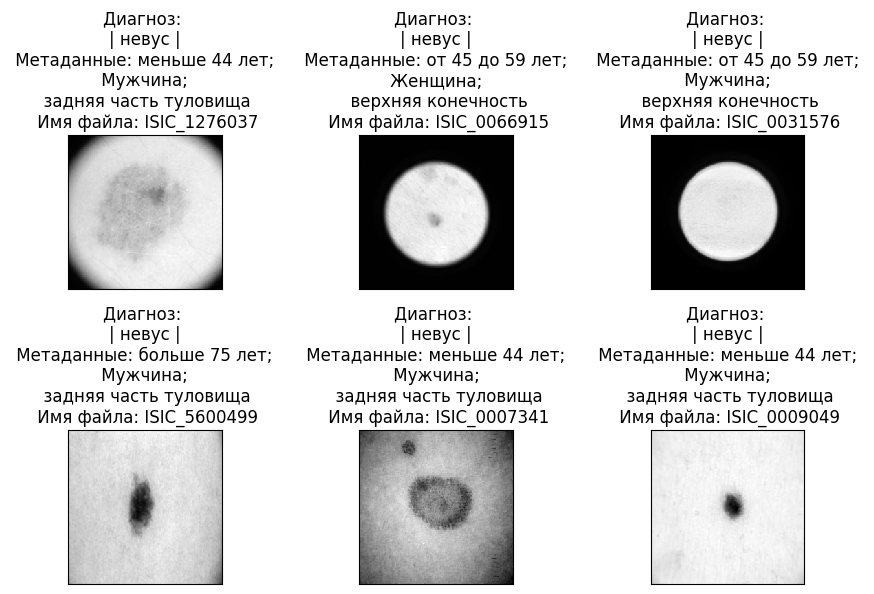

In [12]:
age = ['меньше 44 лет', 'от 45 до 59 лет', 'от 60 до 74 лет', 'больше 75 лет']
sex = ['Мужчина', 'Женщина']
anatomloc = ['торс', 'голова/шея', 'боковая часть туловища', 'нижняя конечность', 'оральная/генитальная зона', 'ладони/подошвы', 'задняя часть туловища', 'верхняя конечность']
lab = ['сосудистое поражение', 'невус', 'солнечное лентиго', 'дерматофиброма', 'себорейный кератоз', 'доброкачественный кератоз', 'актинический кератоз', 'базально-клеточная карцинома', 'плоскоклеточный рак', 'меланома']


examples = enumerate(trainloader)
batch_idx, (example_data, example_meta, example_targets, example_name) = next(examples)

plt.figure(1, figsize=[9,9])
for i in range(6):
    plt.subplot(3, 3, i+1)
    plt.tight_layout()
    plt.imshow(example_data[i][0], cmap='gray', interpolation='none')
    age1 = example_meta[i][0].type(torch.LongTensor)
    sex1 = example_meta[i][1].type(torch.LongTensor)
    anatomloc1 = example_meta[i][2].type(torch.LongTensor)
    plt.title("Диагноз: \n| {} |\n Метаданные: {}; \n {}; \n  {} \n Имя файла: {}".format(lab[example_targets[i]], age[age1], sex[sex1], anatomloc[anatomloc1], example_name[i]))
    plt.xticks([])
    plt.yticks([])

plt.show()

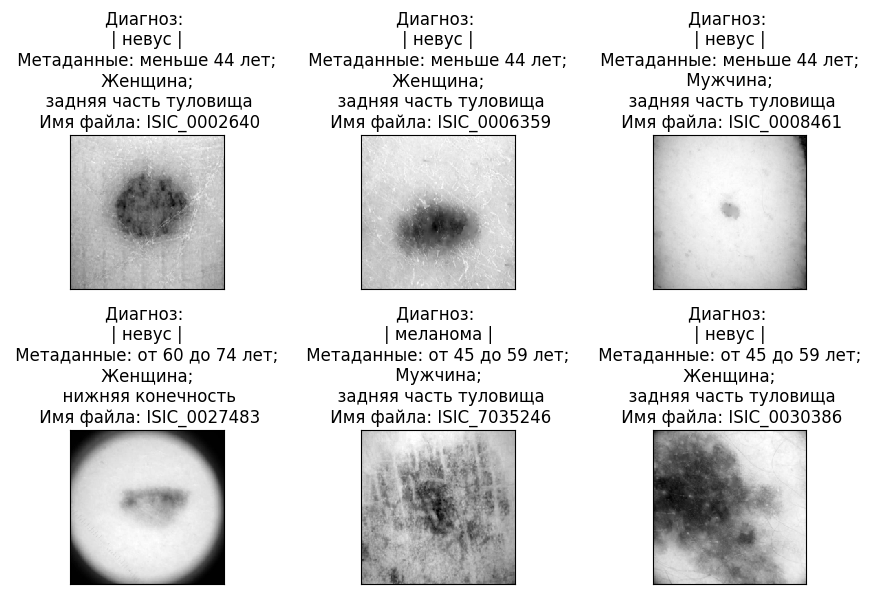

In [13]:
examples = enumerate(valloader)
batch_idx, (example_data, example_meta, example_targets, example_name) = next(examples)

plt.figure(1, figsize=[9,9])
for i in range(6):
    plt.subplot(3, 3, i+1)
    plt.tight_layout()
    plt.imshow(example_data[i][0], cmap='gray', interpolation='none')
    age1 = example_meta[i][0].type(torch.LongTensor)
    sex1 = example_meta[i][1].type(torch.LongTensor)
    anatomloc1 = example_meta[i][2].type(torch.LongTensor)
    plt.title("Диагноз: \n| {} |\n Метаданные: {}; \n {}; \n  {} \n Имя файла: {}".format(lab[example_targets[i]], age[age1], sex[sex1], anatomloc[anatomloc1], example_name[i]))
    plt.xticks([])
    plt.yticks([])

plt.show()

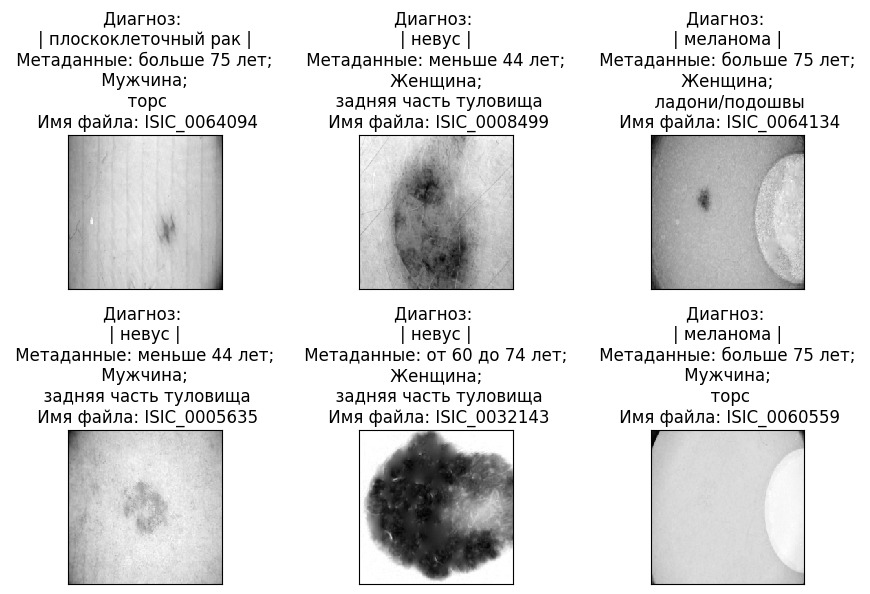

In [14]:
examples = enumerate(testloader)
batch_idx, (example_data, example_meta, example_targets, example_name) = next(examples)

plt.figure(1, figsize=[9,9])
for i in range(6):
    plt.subplot(3, 3, i+1)
    plt.tight_layout()
    plt.imshow(example_data[i][0], cmap='gray', interpolation='none')
    age1 = example_meta[i][0].type(torch.LongTensor)
    sex1 = example_meta[i][1].type(torch.LongTensor)
    anatomloc1 = example_meta[i][2].type(torch.LongTensor)
    plt.title("Диагноз: \n| {} |\n Метаданные: {}; \n {}; \n  {} \n Имя файла: {}".format(lab[example_targets[i]], age[age1], sex[sex1], anatomloc[anatomloc1], example_name[i]))
    plt.xticks([])
    plt.yticks([])

plt.show()

In [15]:
from torchvision.models import resnext101_32x4d, ResNeXt101_32X4D_Weights

resnext101_32x4d = models.resnext101_32x4d(weights=ResNeXt101_32X4D_Weights.IMAGENET1K_V2)

In [16]:
class Classification_M(nn.Module):
    def __init__(self):
        super(Classification_M, self).__init__()
        
        self.layer_1 = nn.Linear(3, 64)
        self.relu1 = nn.ReLU()
        self.batchnorm1 = nn.BatchNorm1d(64)
        
        self.layer_2 = nn.Linear(64, 32)
        self.relu2 = nn.ReLU()
        self.batchnorm2 = nn.BatchNorm1d(32)
        
        self.layer_out = nn.Linear(32, num_classes) 
        
        
    def forward(self, inputs):
        x = self.layer_1(inputs)
        x = self.relu1(x)
        x = self.batchnorm1(x)
        
        x = self.layer_2(x)
        x = self.relu2(x)
        x = self.batchnorm2(x)
        
        x = self.layer_out(x)
        
        return x

Classification_M = Classification_M()    
    
class MultimodalNN(nn.Module):
    def __init__(self):
        super(MultimodalNN, self).__init__()
        
        self.CNN = resnext101_32x4d
        self.outCNN = nn.Linear(1000, num_classes)
        self.meta_net = Classification_M
        self.out = nn.Linear(num_classes+num_classes, num_classes)
                
    def forward(self, img , tab):
        
        img = self.CNN(img)
        img = self.outCNN(img)
        img = img.reshape(img.shape[0], -1)
        
        tab = self.meta_net(tab)
        
        x = torch.cat((img, tab),1)
        x = self.out(x)
        
        return x

torch.manual_seed(42)
nn_deep = MultimodalNN()

model_name = 'NET_deep.pt'
#torch.save(nn_deep.state_dict(), model_name)
model_weights = torch.load(model_name, device)
nn_deep.load_state_dict(model_weights)
nn_deep = nn_deep.to(device)

nn_deep

MultimodalNN(
  (CNN): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): Bottleneck(
        (conv1): Conv2d(64, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
        (bn2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv3): Conv2d(128, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (downsample): Sequ

In [17]:
class Classification_MM(nn.Module):
    def __init__(self):
        super(Classification_MM, self).__init__()
        
        self.layer_1 = nn.Linear(3, 64)
        self.relu1 = nn.ReLU()
        self.batchnorm1 = nn.BatchNorm1d(64)
        
        self.layer_2 = nn.Linear(64, 32)
        self.relu2 = nn.ReLU()
        self.batchnorm2 = nn.BatchNorm1d(32)
        
        self.layer_out = nn.Linear(32, num_classes) 
        
        
    def forward(self, inputs):
        x = self.layer_1(inputs)
        x = self.relu1(x)
        x = self.batchnorm1(x)
        
        x = self.layer_2(x)
        x = self.relu2(x)
        x = self.batchnorm2(x)
        
        x = self.layer_out(x)
        
        return x

Classification_MM = Classification_MM()

class Net(nn.Module):

   def __init__(self):
      super(Net, self).__init__()
      self.layer1 = nn.Sequential(
         nn.Conv2d(3, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(64, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.layer2 = nn.Sequential(
         nn.Conv2d(64, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(128, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.pool1 = nn.AdaptiveAvgPool2d(output_size=(1,1))
      self.fc1 = nn.Linear(128, 32)
      self.fc2 = nn.Linear(32, num_classes)
      self.dropout_rate = 0.5
   
   def forward(self, x):
      x = self.layer1(x)
      x = self.layer2(x)
      x = self.pool1(x)
      x = x.view(x.size(0), -1)
      x = self.fc1(x)
      x = self.fc2(x)
       
      return x
       
LightNN = Net()
    
class MultimodalNN_light(nn.Module):
    def __init__(self):
        super(MultimodalNN_light, self).__init__()
        
        self.CNN = LightNN
       
        self.meta_net = Classification_MM
        
        self.out = nn.Linear(num_classes+num_classes, num_classes)
                
    def forward(self, img , tab):
        
        img = self.CNN(img) 
        img = img.reshape(img.shape[0], -1)
        
        tab = self.meta_net(tab)
        
        x = torch.cat((img, tab),1)
        x = self.out(x)
        
        return x

torch.manual_seed(42)
nn_light = MultimodalNN_light().to(device)

torch.manual_seed(42)
new_nn_light = MultimodalNN_light().to(device)

#model_name = 'Parametr\\nn_light_2.pt'
#torch.save(nn_light.state_dict(), model_name)

nn_light

MultimodalNN_light(
  (CNN): Net(
    (layer1): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU(inplace=True)
      (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (layer2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU(inplace=True)
      (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (pool1): AdaptiveAvgPool2d(output_size=(1, 1))
    (fc1): Linear(in_features=128, out_features=32, bias=True)
    (fc2): Linear(in_features=32, out_features=10, bias=True)
  )
  (meta_net): Classification_MM(
    (layer_1): Linear(in_features=3, out_features=64, bias=True)
    (relu1): ReLU()
  

In [18]:
#print("Норма 1-го слоя в nn_deep:", torch.norm(nn_deep.features[0].weight).item())
#print("Норма 1-го слоя в  nn_light:", torch.norm(nn_light.features[0].weight).item())
#print("Норма 1-го слоя в  new_nn_light:", torch.norm(new_nn_light.features[0].weight).item())

In [19]:
total_params_deep = "{:,}".format(sum(p.numel() for p in nn_deep.parameters()))
print(f"nn_deep параметры: {total_params_deep}")
total_params_light = "{:,}".format(sum(p.numel() for p in nn_light.parameters()))
print(f"nn_light параметры: {total_params_light}")
total_params_light = "{:,}".format(sum(p.numel() for p in new_nn_light.parameters()))
print(f"new_nn_light параметры: {total_params_light}")

nn_deep параметры: 25,041,982
nn_light параметры: 267,686
new_nn_light параметры: 267,686


In [20]:
def train_and_evaluate(model, trainloader, valloader, criterion, optimizer, len_trainset, len_valset, num_epochs=20):

    start_time_glob = time.time()
    model.train()
    
    best_model_wts = copy.deepcopy(model.state_dict())
    
    best_acc = 0.0
    
    for epoch in range(num_epochs):
        
        model.train()
        start_time_tarin = time.time()
        
        print('_' * 120)
        print('Эпоха {}/{}\n'.format(epoch+1, num_epochs))
        
        running_loss = 0.0
        running_corrects = 0
        train_accuracy = 0
        total = 0
        correct_train = 0
        
        for i, data in enumerate(trainloader):
            inputs, feats, labels, name = data
            inputs, feats, labels = inputs.to(device), feats.to(device), labels.to(device)
            
            optimizer.zero_grad()
            outputs = model(inputs, feats)
            loss = criterion(outputs, labels)
            
            _, preds = torch.max(outputs, 1)
            loss.backward() 
            optimizer.step()
            
            running_loss += loss.item() * inputs.size(0)
            running_corrects += torch.sum(preds == labels.data)

            correct_train += preds.eq(labels.data.view_as(preds)).sum()

            total += labels.size(0)
            train_accuracy = 100 * running_corrects / total
            train_accuracy = train_accuracy.cpu()

            if i % 100 == 0:
                print('Тренировочная эпоха: {} [{}/{} ({:.0f}%)]\t\t | Ошибка: {:.4f}\t | Точность распознавания: {:.2f}%'.format(epoch+1, batch_size * i, len_trainset, 100 * i / len(trainloader), loss.item(), train_accuracy))
                
                train_counter.append((i*batch_size) + ((epoch)*len_trainset))
                train_losses.append(loss.item())
                train_acc.append(train_accuracy)
                
        epoch_loss = running_loss / len_trainset
        epoch_acc = running_corrects.double() / len_trainset
        
        time_tarin = time.time()-start_time_tarin
        
        print('\n   Тренировочная ошибка: {:.4f} Точность: {}/{} ({:.2f}%)'.format(epoch_loss, correct_train, len_trainset, 100 * epoch_acc))
        print ('        Время обучения: {}\n'.format(time.strftime("%H:%M:%S", time.gmtime(time_tarin))))
      
        model.eval()
        start_time_test = time.time()
        
        running_loss_val = 0.0 
        running_corrects_val = 0
        correct = 0
        
        with torch.no_grad():
            
            for data in valloader:
                
                inputs, feats, labels, name = data
                inputs, feats, labels = inputs.to(device), feats.to(device), labels.to(device)
            
                outputs = model(inputs, feats)
            
                loss = criterion(outputs,labels)
                _, preds = torch.max(outputs, 1)

                correct += preds.eq(labels.data.view_as(preds)).sum()
            
                running_loss_val += loss.item() * inputs.size(0)
                running_corrects_val += torch.sum(preds == labels.data)
        
            epoch_loss_val = running_loss_val / len_valset
            epoch_acc_val = running_corrects_val.double() / len_valset
            epoch_acc_val_2 = 100 * epoch_acc_val.cpu()

            test_losses.append(epoch_loss_val)
            test_acc.append(epoch_acc_val_2)

            time_test = time.time()-start_time_test
        
            if epoch_acc_val > best_acc:
                best_acc = epoch_acc_val
                best_model_wts = copy.deepcopy(model.state_dict())
            
                torch.save(model.state_dict(), f"BestModel_teacher.pth")

            print('   Валидационная ошибка: {:.4f} Точность: {}/{} ({:.2f}%)'.format(epoch_loss_val, correct, len_valset, 100 * epoch_acc_val))
            print ('        Время тестирования: {}\n'.format(time.strftime("%H:%M:%S", time.gmtime(time_test))))
        
            print('Лучшая валидационная точность: {:.4f}'.format(best_acc))

            torch.save(model.state_dict(), f"teacher_epoch-{epoch+1}.pth")
            model.load_state_dict(best_model_wts)

    time_glob = time.time()-start_time_glob
    print('_' * 120)
    print ('\nОбщее время обучения: {}'.format(time.strftime("%H:%M:%S", time.gmtime(time_glob))))
    
    return model

In [22]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(nn_deep.parameters(), lr=0.001, momentum=0.9)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode = 'min', factor = 0.1, patience = 3)

num_epochs = 50

train_losses = []
train_counter = []
train_acc = []

test_losses = []
test_counter = [i*len_trainset for i in range(num_epochs)]
test_acc = []

NET_deep = train_and_evaluate(nn_deep, trainloader, valloader, criterion, optimizer, len_trainset, len_valset, num_epochs)

________________________________________________________________________________________________________________________
Эпоха 1/10

Тренировочная эпоха: 1 [0/25035 (0%)]		 | Ошибка: 2.3518	 | Точность распознавания: 10.94%
Тренировочная эпоха: 1 [6400/25035 (26%)]		 | Ошибка: 0.6392	 | Точность распознавания: 61.31%
Тренировочная эпоха: 1 [12800/25035 (51%)]		 | Ошибка: 0.6769	 | Точность распознавания: 69.35%
Тренировочная эпоха: 1 [19200/25035 (77%)]		 | Ошибка: 0.7511	 | Точность распознавания: 72.73%

   Тренировочная ошибка: 0.7942 Точность: 18603/25035 (74.31%)
        Время обучения: 00:01:29

   Валидационная ошибка: 0.5286 Точность: 6740/8345 (80.77%)
        Время тестирования: 00:00:11

Лучшая валидационная точность: 0.8077
________________________________________________________________________________________________________________________
Эпоха 2/10

Тренировочная эпоха: 2 [0/25035 (0%)]		 | Ошибка: 0.4027	 | Точность распознавания: 89.06%
Тренировочная эпоха: 2 [6400/2

In [45]:
torch.save(train_losses, 'resnext101\\train_losses.pt')
torch.save(train_counter, 'resnext101\\train_counter.pt')
torch.save(train_acc, 'resnext101\\train_acc.pt')

torch.save(test_losses, 'resnext101\\test_losses.pt')
torch.save(test_counter, 'resnext101\\test_counter.pt')
torch.save(test_acc, 'resnext101\\test_acc.pt')

torch.save(NET_deep.state_dict(), 'resnext101\\NET_deep.pt')

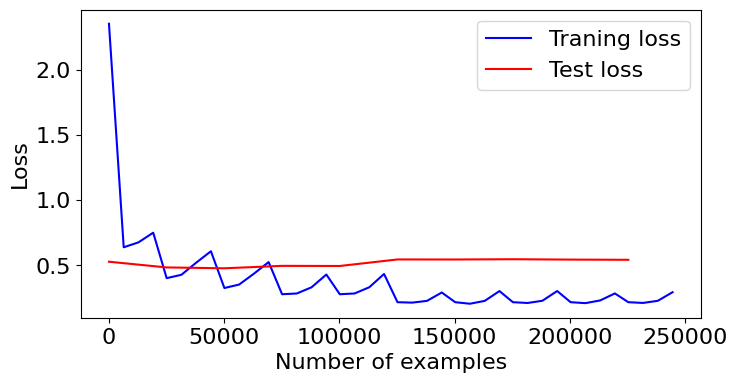

<Figure size 640x480 with 0 Axes>

In [34]:
plt.figure(figsize=(8, 4))
plt.rcParams['font.size'] = '16'
plt.plot(train_counter, train_losses, color='blue')
plt.plot(test_counter, test_losses, color='red')
plt.legend(['Traning loss', 'Test loss'], loc='upper right')
plt.xlabel('Number of examples')
plt.ylabel('Loss')
fig = plt.figure()
plt.show()

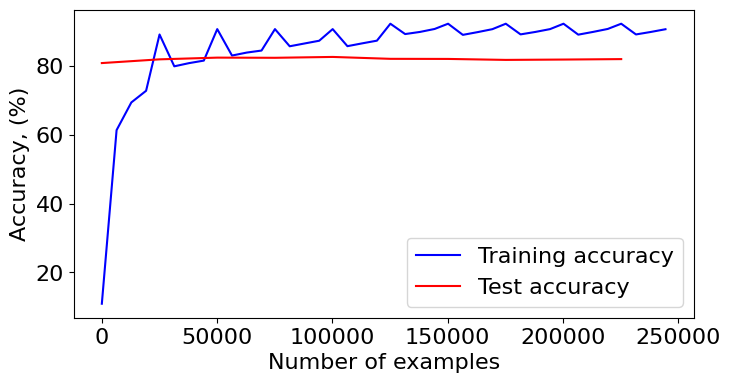

<Figure size 640x480 with 0 Axes>

In [44]:
plt.figure(figsize=(8, 4))
plt.rcParams['font.size'] = '16'
plt.plot(train_counter, train_acc, color='blue')
plt.plot(test_counter, test_acc, color='red')
plt.legend(['Training accuracy', 'Test accuracy'], loc='lower right')
plt.xlabel('Number of examples')
plt.ylabel('Accuracy, (%)')
fig = plt.figure()
plt.show()

In [37]:
def test_NN(model, dataset):
    
    model.eval()
    
    with torch.no_grad():

        for data in dataset:
            image, feats, label, name = data
            image, feats, label = image.to(device), feats.to(device), label.to(device)

            output = model(image, feats)

            pred = (torch.max(torch.exp(output), 1)[1]).cpu().data.numpy()

            predictions.extend(pred)

            label = label.cpu().data.numpy()
            actuals.extend(label)
            
def test_metric():
    
    cm = confusion_matrix(actuals, predictions)
    FP = np.mean(cm.sum(axis=0) - np.diag(cm))  
    FN = np.mean(cm.sum(axis=1) - np.diag(cm))
    TP = np.mean(np.diag(cm))
    TN = np.mean(cm.sum() - (FP + FN + TP))

    Sensitivity = (TP/(TP+FN))
    Specificity = (TN/(TN+FP))
    Precision = (TP/(TP+FP))
    NPV = (TN/(TN+FN))
    PPV = (TP/(TP+FP))
    FNR = (FN/(FN+TP))
    FPR = (FP/(FP+TN))

    F1 = (2*TP)/((2*TP)+FP+FN)

    print('Sensitivity: %.4f' % Sensitivity)
    print('Specificity: %.4f' % Specificity)
    print('Precision: %.4f' % Precision)
    print('NPV: %.4f' % NPV)
    print('PPV: %.4f' % PPV)
    print('FNR: %.4f' % FNR)
    print('FPR: %.4f' % FPR)
    print('F1: %.4f' % F1)


    recall_1 = recall_score(actuals, predictions, average='micro')
    print('Recall micro: %.4f' % recall_1)
    recall_2 = recall_score(actuals, predictions, average='macro')
    print('Recall macro: %.4f' % recall_2)

    precision_1 = precision_score(actuals, predictions, average='micro')
    print('Precision micro: %.4f' % precision_1)
    precision_2 = precision_score(actuals, predictions, average='macro')
    print('Precision macro: %.4f' % precision_2)


    f1_1 = f1_score(actuals, predictions, average='micro')
    print('F1 score micro: %.4f' % f1_1)
    f1_2 = f1_score(actuals, predictions, average='macro')
    print('F1 score macro: %.4f' % f1_2)
    
    jaccard_1 = jaccard_score(actuals, predictions, average='micro')
    print('Jaccard score micro: %.4f' % jaccard_1)
    jaccard_2 = jaccard_score(actuals, predictions, average='macro')
    print('Jaccard score macro: %.4f' % jaccard_2)

    accuracy_1 = accuracy_score(actuals, predictions)
    print('Accuracy score: %.4f' % accuracy_1)

    MCC = matthews_corrcoef(actuals, predictions)
    print('Matthews corrcoef: %.4f' % MCC)

    pre = torch.tensor(predictions)
    ac = torch.tensor(actuals)

    specificity1 = MulticlassSpecificity(average='macro', num_classes=10)
    s1 = specificity1(pre, ac)
    print('Specificity macro: %.4f' % s1)

    specificity2 = MulticlassSpecificity(average='micro', num_classes=10)
    s2 = specificity2(pre, ac)
    print('Specificity micro: %.4f' % s2)

    specificity3 = MulticlassSpecificity(average='weighted', num_classes=10)
    s3 = specificity3(pre, ac)
    print('Specificity weighted: %.4f' % s3)

    specificity4 = MulticlassSpecificity(average='none', num_classes=10)
    s4 = specificity4(pre, ac)
    print('Specificity none - class vascular lesions (0): %.4f' % s4[0])
    print('Specificity none - class nevus (1): %.4f' % s4[1])
    print('Specificity none - class solar lentigo (2): %.4f' % s4[2])
    print('Specificity none - class dermatofibroma (3): %.4f' % s4[3])
    print('Specificity none - class seborrheic ketarosis (4): %.4f' % s4[4])
    print('Specificity none - class benign ketarosis (5): %.4f' % s4[5])
    print('Specificity none - class actinic keratosis (6): %.4f' % s4[6])
    print('Specificity none - class basal cell carcinoma (7): %.4f' % s4[7])
    print('Specificity none - class squamous cell carcinoma (8): %.4f' % s4[8])
    print('Specificity none - class melanoma (9): %.4f' % s4[9])

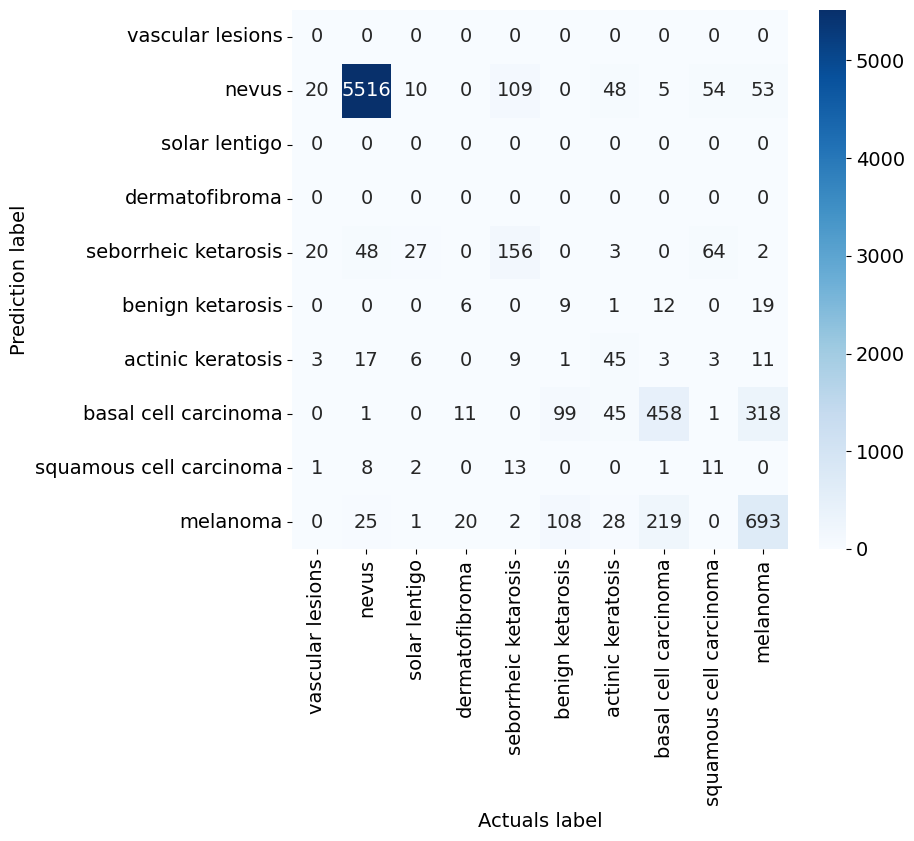

Sensitivity: 0.8254
Specificity: 0.9806
Precision: 0.8254
NPV: 0.9806
PPV: 0.8254
FNR: 0.1746
FPR: 0.0194
F1: 0.8254
Recall micro: 0.8254
Recall macro: 0.3200
Precision micro: 0.8254
Precision macro: 0.3515
F1 score micro: 0.8254
F1 score macro: 0.3206
Jaccard score micro: 0.7027
Jaccard score macro: 0.2437
Accuracy score: 0.8254
Matthews corrcoef: 0.6545
Specificity macro: 0.9738
Specificity micro: 0.9806
Specificity weighted: 0.9128
Specificity none - class vascular lesions (0): 1.0000
Specificity none - class nevus (1): 0.8905
Specificity none - class solar lentigo (2): 1.0000
Specificity none - class dermatofibroma (3): 1.0000
Specificity none - class seborrheic ketarosis (4): 0.9796
Specificity none - class benign ketarosis (5): 0.9953
Specificity none - class actinic keratosis (6): 0.9935
Specificity none - class basal cell carcinoma (7): 0.9379
Specificity none - class squamous cell carcinoma (8): 0.9970
Specificity none - class melanoma (9): 0.9444


C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [38]:
actuals = []
predictions = []

NET_deep = nn_deep

test_NN(NET_deep, testloader)

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

test_metric()

In [50]:
train_losses = []
train_counter = []
train_acc = []

test_losses = []
test_counter = [i*len_trainset for i in range(num_epochs)]
test_acc = []


criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(nn_light.parameters(), lr=0.001, momentum=0.9)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode = 'min', factor = 0.1, patience = 3)

NET_light = train_and_evaluate(nn_light, trainloader, valloader, criterion, optimizer, len_trainset, len_valset, 10)

________________________________________________________________________________________________________________________
Эпоха 1/10

Тренировочная эпоха: 1 [0/25035 (0%)]		 | Ошибка: 0.8311	 | Точность распознавания: 70.31%
Тренировочная эпоха: 1 [6400/25035 (26%)]		 | Ошибка: 0.9304	 | Точность распознавания: 68.77%
Тренировочная эпоха: 1 [12800/25035 (51%)]		 | Ошибка: 0.9589	 | Точность распознавания: 69.17%
Тренировочная эпоха: 1 [19200/25035 (77%)]		 | Ошибка: 1.0873	 | Точность распознавания: 69.69%

   Тренировочная ошибка: 0.9427 Точность: 17436/25035 (69.65%)
        Время обучения: 00:00:59

   Валидационная ошибка: 0.8840 Точность: 5915/8345 (70.88%)
        Время тестирования: 00:00:09

Лучшая валидационная точность: 0.7088
________________________________________________________________________________________________________________________
Эпоха 2/10

Тренировочная эпоха: 2 [0/25035 (0%)]		 | Ошибка: 0.7592	 | Точность распознавания: 75.00%
Тренировочная эпоха: 2 [6400/2

In [58]:
torch.save(train_losses, 'LightModel_Res\\train_losses.pt')
torch.save(train_counter, 'LightModel_Res\\train_counter.pt')
torch.save(train_acc, 'LightModel_Res\\train_acc.pt')

torch.save(test_losses, 'LightModel_Res\\test_losses.pt')
torch.save(test_counter, 'LightModel_Res\\test_counter.pt')
torch.save(test_acc, 'LightModel_Res\\test_acc.pt')

torch.save(NET_light.state_dict(), 'LightModel_Res\\NET_light.pt')
torch.save(NET_deep.state_dict(), 'resnext101\\NET_deep.pt')

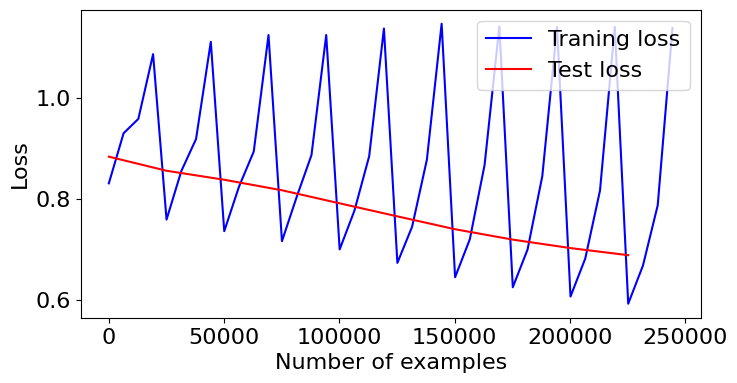

<Figure size 640x480 with 0 Axes>

In [56]:
plt.figure(figsize=(8, 4))
plt.rcParams['font.size'] = '16'
plt.plot(train_counter, train_losses, color='blue')
plt.plot(test_counter, test_losses, color='red')
plt.legend(['Traning loss', 'Test loss'], loc='upper right')
plt.xlabel('Number of examples')
plt.ylabel('Loss')
fig = plt.figure()
plt.show()

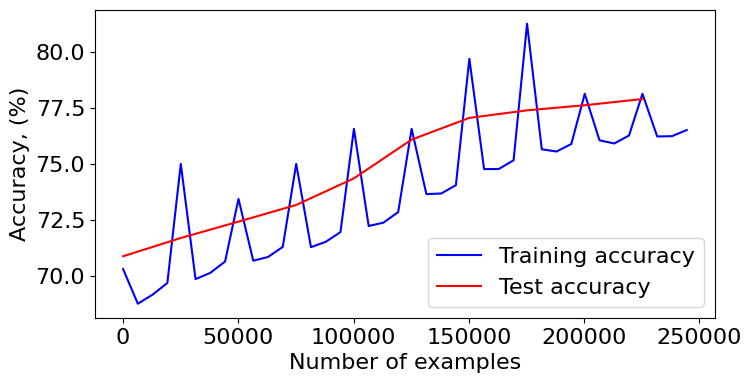

<Figure size 640x480 with 0 Axes>

In [57]:
plt.figure(figsize=(8, 4))
plt.rcParams['font.size'] = '16'
plt.plot(train_counter, train_acc, color='blue')
plt.plot(test_counter, test_acc, color='red')
plt.legend(['Training accuracy', 'Test accuracy'], loc='lower right')
plt.xlabel('Number of examples')
plt.ylabel('Accuracy, (%)')
fig = plt.figure()
plt.show()

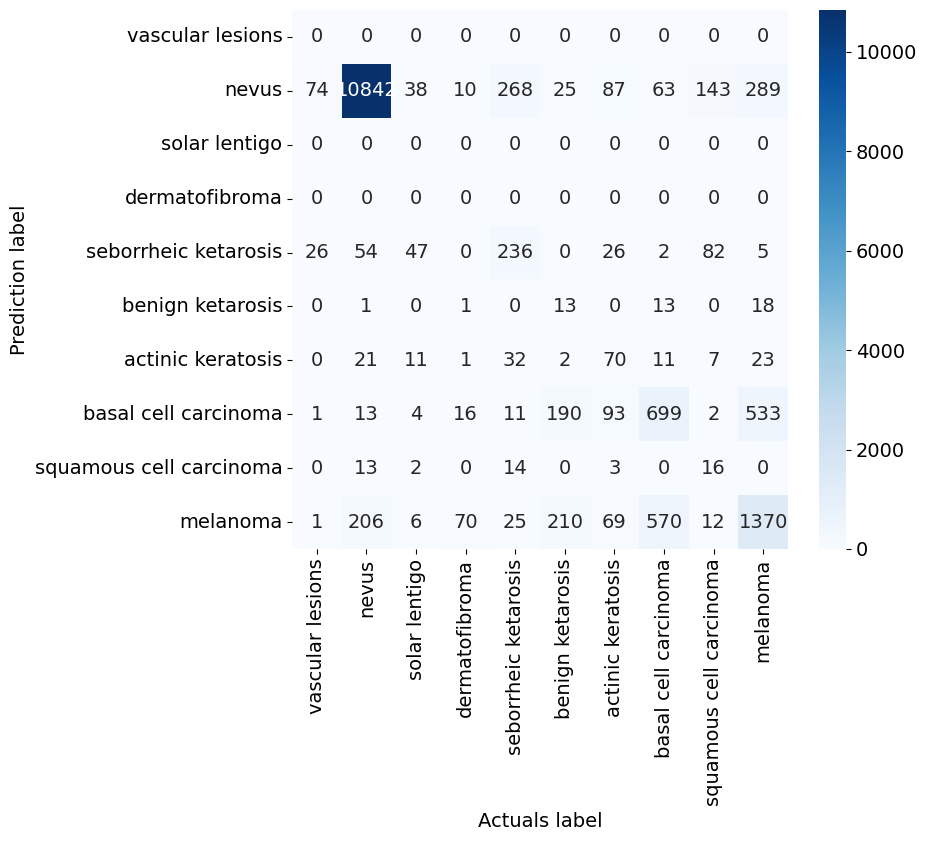

Sensitivity: 0.7936
Specificity: 0.9771
Precision: 0.7936
NPV: 0.9771
PPV: 0.7936
FNR: 0.2064
FPR: 0.0229
F1: 0.7936
Recall micro: 0.7936
Recall macro: 0.2794
Precision micro: 0.7936
Precision macro: 0.3406
F1 score micro: 0.7936
F1 score macro: 0.2862
Jaccard score micro: 0.6579
Jaccard score macro: 0.2130
Accuracy score: 0.7936
Matthews corrcoef: 0.5876
Specificity macro: 0.9657
Specificity micro: 0.9771
Specificity weighted: 0.8636
Specificity none - class vascular lesions (0): 1.0000
Specificity none - class nevus (1): 0.8200
Specificity none - class solar lentigo (2): 1.0000
Specificity none - class dermatofibroma (3): 1.0000
Specificity none - class seborrheic ketarosis (4): 0.9850
Specificity none - class benign ketarosis (5): 0.9980
Specificity none - class actinic keratosis (6): 0.9934
Specificity none - class basal cell carcinoma (7): 0.9437
Specificity none - class squamous cell carcinoma (8): 0.9981
Specificity none - class melanoma (9): 0.9191


C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [59]:
def test_NN(model):
    
    model.eval()
    
    with torch.no_grad():

        for data in testloader:
            image, feats, label, name = data
            image, feats, label = image.to(device), feats.to(device), label.to(device)

            output = model(image, feats)

            pred = (torch.max(torch.exp(output), 1)[1]).cpu().data.numpy()

            predictions.extend(pred)

            label = label.cpu().data.numpy()
            actuals.extend(label)


test_NN(nn_light)

torch.save(actuals, 'LightModel_Res\\actuals.pt')
torch.save(predictions, 'LightModel_Res\\predictions.pt')

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

torch.save(matrix, 'LightModel_Res\\matrix.pt')

test_metric()

In [27]:
def loss_kd(outputs, labels, teacher_outputs, temparature, alpha):
    
    KD_loss = nn.KLDivLoss(reduction='batchmean')(F.log_softmax(outputs/temparature, dim=1), F.softmax(teacher_outputs/temparature,dim=1)) * (alpha * temparature * temparature) + F.cross_entropy(outputs, labels) * (1. - alpha)
    
    return KD_loss

def get_outputs(model, dataloader):
    outputs = []
    
    for inputs, feats, labels, name in dataloader:
        inputs_batch, feats_batch, labels_batch = inputs.cuda(), feats.cuda(), labels.cuda()
        output_batch = model(inputs_batch, feats_batch).data.cpu().numpy()
        outputs.append(output_batch)
       
    return outputs

In [28]:
import torch.nn.functional as F

def train_kd(model, teacher_out, optimizer, loss_kd, dataloader, temparature, alpha):
    
    model.train()
    start_time_tarin = time.time()
    
    running_loss = 0.0
    running_corrects = 0
    
    for i, data in enumerate(dataloader):
        inputs, feats, labels, name = data
        inputs, feats, labels = inputs.to(device), feats.to(device), labels.to(device)
        
        optimizer.zero_grad()
        
        outputs = model(inputs, feats)
        outputs_teacher = torch.from_numpy(teacher_out[i]).to(device)
        
        loss = loss_kd(outputs, labels, outputs_teacher, temparature, alpha)
        _, preds = torch.max(outputs, 1)
        
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * inputs.size(0)
        running_corrects += torch.sum(preds == labels.data)
   
    epoch_loss = running_loss / len_trainset
    epoch_acc = running_corrects.double() / len_trainset
    time_tarin = time.time()-start_time_tarin
    
    print('   Тренировочная ошибка: {:.4f} Точность: {:.4f}'.format(epoch_loss, epoch_acc))
    print ('        Время обучения: {}'.format(time.strftime("%H:%M:%S", time.gmtime(time_tarin))))
    
def eval_kd(model,teacher_out, optimizer, loss_kd, dataloader, temparature, alpha):
    
    model.eval()
    start_time_test = time.time()
    
    running_loss = 0.0
    running_corrects = 0
    
    for i, data in enumerate(dataloader):
        inputs, feats, labels, name = data
        inputs, feats, labels = inputs.to(device), feats.to(device), labels.to(device)
        
        outputs = model(inputs, feats)
        outputs_teacher = torch.from_numpy(teacher_out[i]).cuda()
        
        loss = loss_kd(outputs,labels,outputs_teacher,temparature, alpha)
        _, preds = torch.max(outputs, 1)
        
        running_loss += loss.item() * inputs.size(0)
        running_corrects += torch.sum(preds == labels.data)
        
    epoch_loss = running_loss / len_valset
    epoch_acc = running_corrects.double() / len_valset

    time_test = time.time()-start_time_test
    
    print('   Валидационная ошибка: {:.4f} Точность: {:.4f}'.format(epoch_loss, epoch_acc))
    print ('        Время тестирования: {}\n'.format(time.strftime("%H:%M:%S", time.gmtime(time_test))))
    
    return epoch_acc


def train_and_evaluate_kd(model, teacher_model, optimizer, loss_kd, trainloader, valloader, temparature, alpha, num_epochs=20):

    teacher_model.eval()
    start_time_glob = time.time()
    start_time_teacher_model = time.time()
    
    print('Процесс вывода весов с архитектуры-учителя...')
    
    best_model_wts = copy.deepcopy(model.state_dict())
    outputs_teacher_train = get_outputs(teacher_model, trainloader)
    outputs_teacher_val = get_outputs(teacher_model, valloader)

    time_teacher_model = time.time()-start_time_teacher_model
    print ('Время вывода весов с архитектуры-учителя: {}'.format(time.strftime("%H:%M:%S", time.gmtime(time_teacher_model))))
    
    best_acc = 0.0
    
    for epoch in range(num_epochs):

        print('_' * 60)
        print('Эпоха {}/{}'.format(epoch+1, num_epochs))
        
        train_kd(model, outputs_teacher_train, optimizer, loss_kd, trainloader, temparature, alpha)
        epoch_acc_val = eval_kd(model, outputs_teacher_val, optimizer, loss_kd, valloader, temparature, alpha)

        torch.save(model.state_dict(), f"student_epoch-{epoch+1}.pth")
        
        if epoch_acc_val > best_acc:
            best_acc = epoch_acc_val
            best_model_wts = copy.deepcopy(model.state_dict())
            
            torch.save(model.state_dict(), f"BestModel_student.pth")
            
        model.load_state_dict(best_model_wts)
            
        print('Лучшая валидационная точность: {:.4f}'.format(best_acc))
        
    time_glob = time.time()-start_time_glob
    print('_' * 60)
    print ('\nОбщее время обучения: {}'.format(time.strftime("%H:%M:%S", time.gmtime(time_glob))))
    
    return model

In [29]:
optimizer = torch.optim.SGD(new_nn_light.parameters(), lr=0.001, momentum=0.9)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode = 'min', factor = 0.1, patience = 3)

STUD_Model_1 = train_and_evaluate_kd (new_nn_light, NET_deep, optimizer, loss_kd, trainloader, valloader, 1, 0.5, 50)

Процесс вывода весов с архитектуры-учителя...
Время вывода весов с архитектуры-учителя: 00:00:46
____________________________________________________________
Эпоха 1/20
   Тренировочная ошибка: 1.1769 Точность: 0.6113
        Время обучения: 00:01:00
   Валидационная ошибка: 0.7685 Точность: 0.6993
        Время тестирования: 00:00:09

Лучшая валидационная точность: 0.6993
____________________________________________________________
Эпоха 2/20
   Тренировочная ошибка: 0.7520 Точность: 0.6954
        Время обучения: 00:01:00
   Валидационная ошибка: 0.6976 Точность: 0.7062
        Время тестирования: 00:00:09

Лучшая валидационная точность: 0.7062
____________________________________________________________
Эпоха 3/20
   Тренировочная ошибка: 0.7068 Точность: 0.7073
        Время обучения: 00:01:00
   Валидационная ошибка: 0.6725 Точность: 0.7150
        Время тестирования: 00:00:09

Лучшая валидационная точность: 0.7150
____________________________________________________________
Эпоха

In [30]:
class Classification_MM(nn.Module):
    def __init__(self):
        super(Classification_MM, self).__init__()
        
        self.layer_1 = nn.Linear(3, 64)
        self.relu1 = nn.ReLU()
        self.batchnorm1 = nn.BatchNorm1d(64)
        
        self.layer_2 = nn.Linear(64, 32)
        self.relu2 = nn.ReLU()
        self.batchnorm2 = nn.BatchNorm1d(32)
        
        self.layer_out = nn.Linear(32, num_classes) 
        
        
    def forward(self, inputs):
        x = self.layer_1(inputs)
        x = self.relu1(x)
        x = self.batchnorm1(x)
        
        x = self.layer_2(x)
        x = self.relu2(x)
        x = self.batchnorm2(x)
        
        x = self.layer_out(x)
        
        return x

Classification_MM = Classification_MM()

class Net(nn.Module):

   def __init__(self):
      super(Net, self).__init__()
      self.layer1 = nn.Sequential(
         nn.Conv2d(3, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(64, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.layer2 = nn.Sequential(
         nn.Conv2d(64, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(128, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.pool1 = nn.AdaptiveAvgPool2d(output_size=(1,1))
      self.fc1 = nn.Linear(128, 32)
      self.fc2 = nn.Linear(32, num_classes)
      self.dropout_rate = 0.5
   
   def forward(self, x):
      x = self.layer1(x)
      x = self.layer2(x)
      x = self.pool1(x)
      x = x.view(x.size(0), -1)
      x = self.fc1(x)
      x = self.fc2(x)
       
      return x
       
LightNN = Net()
    
class MultimodalNN_light(nn.Module):
    def __init__(self):
        super(MultimodalNN_light, self).__init__()
        
        self.CNN = LightNN
       
        self.meta_net = Classification_MM
        
        self.out = nn.Linear(num_classes+num_classes, num_classes)
                
    def forward(self, img , tab):
        
        img = self.CNN(img) 
        img = img.reshape(img.shape[0], -1)
        
        tab = self.meta_net(tab)
        
        x = torch.cat((img, tab),1)
        x = self.out(x)
        
        return x

torch.manual_seed(42)
new_nn_light_2 = MultimodalNN_light().to(device)

In [31]:
optimizer = torch.optim.SGD(new_nn_light_2.parameters(), lr=0.001, momentum=0.9)

STUD_Model_2 = train_and_evaluate_kd (new_nn_light_2, NET_deep, optimizer, loss_kd, trainloader, valloader, 2, 0.5, 50)

Процесс вывода весов с архитектуры-учителя...
Время вывода весов с архитектуры-учителя: 00:00:46
____________________________________________________________
Эпоха 1/20
   Тренировочная ошибка: 1.9913 Точность: 0.6365
        Время обучения: 00:01:00
   Валидационная ошибка: 1.2658 Точность: 0.7132
        Время тестирования: 00:00:09

Лучшая валидационная точность: 0.7132
____________________________________________________________
Эпоха 2/20
   Тренировочная ошибка: 1.2871 Точность: 0.7100
        Время обучения: 00:01:00
   Валидационная ошибка: 1.2039 Точность: 0.7202
        Время тестирования: 00:00:09

Лучшая валидационная точность: 0.7202
____________________________________________________________
Эпоха 3/20
   Тренировочная ошибка: 1.2307 Точность: 0.7200
        Время обучения: 00:01:00
   Валидационная ошибка: 1.1572 Точность: 0.7348
        Время тестирования: 00:00:09

Лучшая валидационная точность: 0.7348
____________________________________________________________
Эпоха

In [34]:
class Classification_MM(nn.Module):
    def __init__(self):
        super(Classification_MM, self).__init__()
        
        self.layer_1 = nn.Linear(3, 64)
        self.relu1 = nn.ReLU()
        self.batchnorm1 = nn.BatchNorm1d(64)
        
        self.layer_2 = nn.Linear(64, 32)
        self.relu2 = nn.ReLU()
        self.batchnorm2 = nn.BatchNorm1d(32)
        
        self.layer_out = nn.Linear(32, num_classes) 
        
        
    def forward(self, inputs):
        x = self.layer_1(inputs)
        x = self.relu1(x)
        x = self.batchnorm1(x)
        
        x = self.layer_2(x)
        x = self.relu2(x)
        x = self.batchnorm2(x)
        
        x = self.layer_out(x)
        
        return x

Classification_MM = Classification_MM()

class Net(nn.Module):

   def __init__(self):
      super(Net, self).__init__()
      self.layer1 = nn.Sequential(
         nn.Conv2d(3, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(64, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.layer2 = nn.Sequential(
         nn.Conv2d(64, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(128, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.pool1 = nn.AdaptiveAvgPool2d(output_size=(1,1))
      self.fc1 = nn.Linear(128, 32)
      self.fc2 = nn.Linear(32, num_classes)
      self.dropout_rate = 0.5
   
   def forward(self, x):
      x = self.layer1(x)
      x = self.layer2(x)
      x = self.pool1(x)
      x = x.view(x.size(0), -1)
      x = self.fc1(x)
      x = self.fc2(x)
       
      return x
       
LightNN = Net()
    
class MultimodalNN_light(nn.Module):
    def __init__(self):
        super(MultimodalNN_light, self).__init__()
        
        self.CNN = LightNN
       
        self.meta_net = Classification_MM
        
        self.out = nn.Linear(num_classes+num_classes, num_classes)
                
    def forward(self, img , tab):
        
        img = self.CNN(img) 
        img = img.reshape(img.shape[0], -1)
        
        tab = self.meta_net(tab)
        
        x = torch.cat((img, tab),1)
        x = self.out(x)
        
        return x

torch.manual_seed(42)
new_nn_light_3 = MultimodalNN_light().to(device)

In [35]:
optimizer = torch.optim.SGD(new_nn_light_3.parameters(), lr=0.001, momentum=0.9)

STUD_Model_3 = train_and_evaluate_kd (new_nn_light_3, NET_deep, optimizer, loss_kd, trainloader, valloader, 5, 0.5, 50)

Процесс вывода весов с архитектуры-учителя...
Время вывода весов с архитектуры-учителя: 00:00:46
____________________________________________________________
Эпоха 1/20
   Тренировочная ошибка: 4.2333 Точность: 0.6270
        Время обучения: 00:01:00
   Валидационная ошибка: 2.7113 Точность: 0.7015
        Время тестирования: 00:00:09

Лучшая валидационная точность: 0.7015
____________________________________________________________
Эпоха 2/20
   Тренировочная ошибка: 2.6805 Точность: 0.7033
        Время обучения: 00:01:00
   Валидационная ошибка: 2.4785 Точность: 0.7206
        Время тестирования: 00:00:09

Лучшая валидационная точность: 0.7206
____________________________________________________________
Эпоха 3/20
   Тренировочная ошибка: 2.4544 Точность: 0.7234
        Время обучения: 00:01:00
   Валидационная ошибка: 2.2478 Точность: 0.7408
        Время тестирования: 00:00:09

Лучшая валидационная точность: 0.7408
____________________________________________________________
Эпоха

In [36]:
class Classification_MM(nn.Module):
    def __init__(self):
        super(Classification_MM, self).__init__()
        
        self.layer_1 = nn.Linear(3, 64)
        self.relu1 = nn.ReLU()
        self.batchnorm1 = nn.BatchNorm1d(64)
        
        self.layer_2 = nn.Linear(64, 32)
        self.relu2 = nn.ReLU()
        self.batchnorm2 = nn.BatchNorm1d(32)
        
        self.layer_out = nn.Linear(32, num_classes) 
        
        
    def forward(self, inputs):
        x = self.layer_1(inputs)
        x = self.relu1(x)
        x = self.batchnorm1(x)
        
        x = self.layer_2(x)
        x = self.relu2(x)
        x = self.batchnorm2(x)
        
        x = self.layer_out(x)
        
        return x

Classification_MM = Classification_MM()

class Net(nn.Module):

   def __init__(self):
      super(Net, self).__init__()
      self.layer1 = nn.Sequential(
         nn.Conv2d(3, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(64, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.layer2 = nn.Sequential(
         nn.Conv2d(64, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(128, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.pool1 = nn.AdaptiveAvgPool2d(output_size=(1,1))
      self.fc1 = nn.Linear(128, 32)
      self.fc2 = nn.Linear(32, num_classes)
      self.dropout_rate = 0.5
   
   def forward(self, x):
      x = self.layer1(x)
      x = self.layer2(x)
      x = self.pool1(x)
      x = x.view(x.size(0), -1)
      x = self.fc1(x)
      x = self.fc2(x)
       
      return x
       
LightNN = Net()
    
class MultimodalNN_light(nn.Module):
    def __init__(self):
        super(MultimodalNN_light, self).__init__()
        
        self.CNN = LightNN
       
        self.meta_net = Classification_MM
        
        self.out = nn.Linear(num_classes+num_classes, num_classes)
                
    def forward(self, img , tab):
        
        img = self.CNN(img) 
        img = img.reshape(img.shape[0], -1)
        
        tab = self.meta_net(tab)
        
        x = torch.cat((img, tab),1)
        x = self.out(x)
        
        return x

torch.manual_seed(42)
new_nn_light_4 = MultimodalNN_light().to(device)

In [37]:
optimizer = torch.optim.SGD(new_nn_light_4.parameters(), lr=0.001, momentum=0.9)

STUD_Model_4 = train_and_evaluate_kd (new_nn_light_4, NET_deep, optimizer, loss_kd, trainloader, valloader, 2, 0.25, 50)

Процесс вывода весов с архитектуры-учителя...
Время вывода весов с архитектуры-учителя: 00:00:46
____________________________________________________________
Эпоха 1/20
   Тренировочная ошибка: 1.6356 Точность: 0.6473
        Время обучения: 00:01:00
   Валидационная ошибка: 1.1174 Точность: 0.7084
        Время тестирования: 00:00:09

Лучшая валидационная точность: 0.7084
____________________________________________________________
Эпоха 2/20
   Тренировочная ошибка: 1.1244 Точность: 0.7082
        Время обучения: 00:01:00
   Валидационная ошибка: 1.0623 Точность: 0.7186
        Время тестирования: 00:00:09

Лучшая валидационная точность: 0.7186
____________________________________________________________
Эпоха 3/20
   Тренировочная ошибка: 1.0891 Точность: 0.7124
        Время обучения: 00:01:00
   Валидационная ошибка: 1.0303 Точность: 0.7252
        Время тестирования: 00:00:09

Лучшая валидационная точность: 0.7252
____________________________________________________________
Эпоха

In [38]:
class Classification_MM(nn.Module):
    def __init__(self):
        super(Classification_MM, self).__init__()
        
        self.layer_1 = nn.Linear(3, 64)
        self.relu1 = nn.ReLU()
        self.batchnorm1 = nn.BatchNorm1d(64)
        
        self.layer_2 = nn.Linear(64, 32)
        self.relu2 = nn.ReLU()
        self.batchnorm2 = nn.BatchNorm1d(32)
        
        self.layer_out = nn.Linear(32, num_classes) 
        
        
    def forward(self, inputs):
        x = self.layer_1(inputs)
        x = self.relu1(x)
        x = self.batchnorm1(x)
        
        x = self.layer_2(x)
        x = self.relu2(x)
        x = self.batchnorm2(x)
        
        x = self.layer_out(x)
        
        return x

Classification_MM = Classification_MM()

class Net(nn.Module):

   def __init__(self):
      super(Net, self).__init__()
      self.layer1 = nn.Sequential(
         nn.Conv2d(3, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(64, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.layer2 = nn.Sequential(
         nn.Conv2d(64, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(128, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.pool1 = nn.AdaptiveAvgPool2d(output_size=(1,1))
      self.fc1 = nn.Linear(128, 32)
      self.fc2 = nn.Linear(32, num_classes)
      self.dropout_rate = 0.5
   
   def forward(self, x):
      x = self.layer1(x)
      x = self.layer2(x)
      x = self.pool1(x)
      x = x.view(x.size(0), -1)
      x = self.fc1(x)
      x = self.fc2(x)
       
      return x
       
LightNN = Net()
    
class MultimodalNN_light(nn.Module):
    def __init__(self):
        super(MultimodalNN_light, self).__init__()
        
        self.CNN = LightNN
       
        self.meta_net = Classification_MM
        
        self.out = nn.Linear(num_classes+num_classes, num_classes)
                
    def forward(self, img , tab):
        
        img = self.CNN(img) 
        img = img.reshape(img.shape[0], -1)
        
        tab = self.meta_net(tab)
        
        x = torch.cat((img, tab),1)
        x = self.out(x)
        
        return x

torch.manual_seed(42)
new_nn_light_5 = MultimodalNN_light().to(device)

In [39]:
optimizer = torch.optim.SGD(new_nn_light_5.parameters(), lr=0.001, momentum=0.9)

STUD_Model_5 = train_and_evaluate_kd (new_nn_light_5, NET_deep, optimizer, loss_kd, trainloader, valloader, 2, 0.75, 50)

Процесс вывода весов с архитектуры-учителя...
Время вывода весов с архитектуры-учителя: 00:00:46
____________________________________________________________
Эпоха 1/20
   Тренировочная ошибка: 2.1475 Точность: 0.6578
        Время обучения: 00:01:00
   Валидационная ошибка: 1.4197 Точность: 0.7119
        Время тестирования: 00:00:09

Лучшая валидационная точность: 0.7119
____________________________________________________________
Эпоха 2/20
   Тренировочная ошибка: 1.4444 Точность: 0.7089
        Время обучения: 00:01:00
   Валидационная ошибка: 1.3520 Точность: 0.7197
        Время тестирования: 00:00:09

Лучшая валидационная точность: 0.7197
____________________________________________________________
Эпоха 3/20
   Тренировочная ошибка: 1.3797 Точность: 0.7169
        Время обучения: 00:01:00
   Валидационная ошибка: 1.2939 Точность: 0.7297
        Время тестирования: 00:00:09

Лучшая валидационная точность: 0.7297
____________________________________________________________
Эпоха

In [29]:
class Classification_MM(nn.Module):
    def __init__(self):
        super(Classification_MM, self).__init__()
        
        self.layer_1 = nn.Linear(3, 64)
        self.relu1 = nn.ReLU()
        self.batchnorm1 = nn.BatchNorm1d(64)
        
        self.layer_2 = nn.Linear(64, 32)
        self.relu2 = nn.ReLU()
        self.batchnorm2 = nn.BatchNorm1d(32)
        
        self.layer_out = nn.Linear(32, num_classes) 
        
        
    def forward(self, inputs):
        x = self.layer_1(inputs)
        x = self.relu1(x)
        x = self.batchnorm1(x)
        
        x = self.layer_2(x)
        x = self.relu2(x)
        x = self.batchnorm2(x)
        
        x = self.layer_out(x)
        
        return x

Classification_MM = Classification_MM()

class Net(nn.Module):

   def __init__(self):
      super(Net, self).__init__()
      self.layer1 = nn.Sequential(
         nn.Conv2d(3, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(64, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.layer2 = nn.Sequential(
         nn.Conv2d(64, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(128, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.pool1 = nn.AdaptiveAvgPool2d(output_size=(1,1))
      self.fc1 = nn.Linear(128, 32)
      self.fc2 = nn.Linear(32, num_classes)
      self.dropout_rate = 0.5
   
   def forward(self, x):
      x = self.layer1(x)
      x = self.layer2(x)
      x = self.pool1(x)
      x = x.view(x.size(0), -1)
      x = self.fc1(x)
      x = self.fc2(x)
       
      return x
       
LightNN = Net()
    
class MultimodalNN_light(nn.Module):
    def __init__(self):
        super(MultimodalNN_light, self).__init__()
        
        self.CNN = LightNN
       
        self.meta_net = Classification_MM
        
        self.out = nn.Linear(num_classes+num_classes, num_classes)
                
    def forward(self, img , tab):
        
        img = self.CNN(img) 
        img = img.reshape(img.shape[0], -1)
        
        tab = self.meta_net(tab)
        
        x = torch.cat((img, tab),1)
        x = self.out(x)
        
        return x


torch.manual_seed(42)
NET_light = MultimodalNN_light()

model_name = 'NET_light.pt'
model_weights = torch.load(model_name, device)
NET_light.load_state_dict(model_weights)
NET_light = NET_light.to(device)

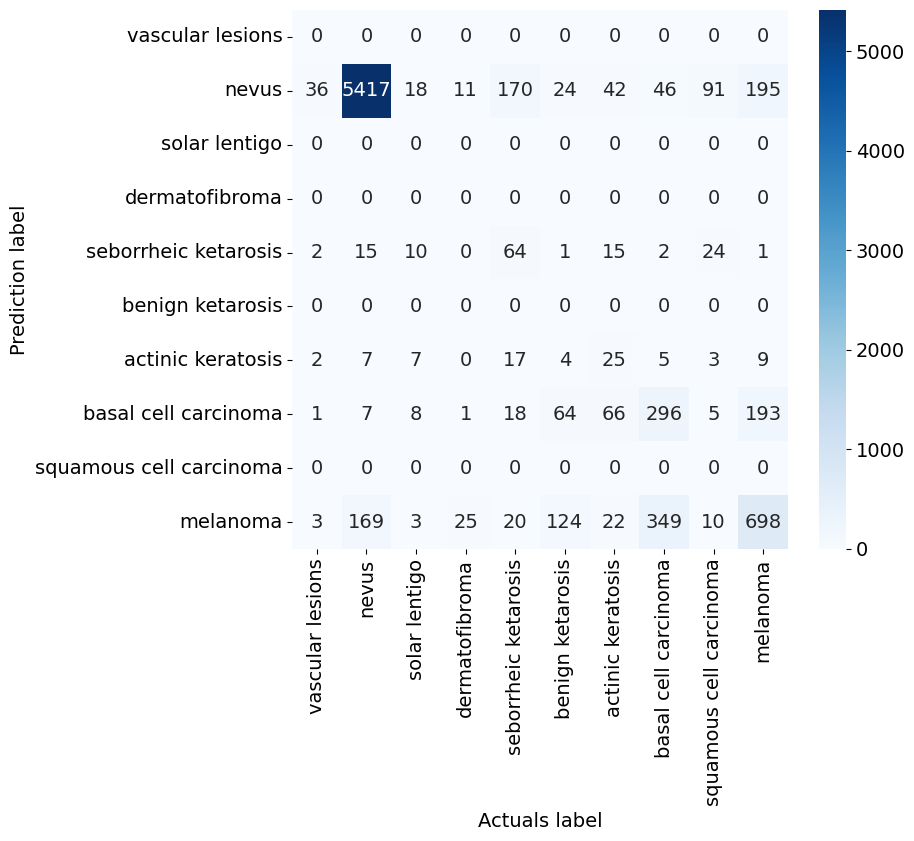

Sensitivity: 0.7789
Specificity: 0.9754
Precision: 0.7789
NPV: 0.9754
PPV: 0.7789
FNR: 0.2211
FPR: 0.0246
F1: 0.7789
Recall micro: 0.7789
Recall macro: 0.2394
Precision micro: 0.7789
Precision macro: 0.2629
F1 score micro: 0.7789
F1 score macro: 0.2423
Jaccard score micro: 0.6379
Jaccard score macro: 0.1819
Accuracy score: 0.7789
Matthews corrcoef: 0.5470
Specificity macro: 0.9605
Specificity micro: 0.9754
Specificity weighted: 0.8264
Specificity none - class vascular lesions (0): 1.0000
Specificity none - class nevus (1): 0.7681
Specificity none - class solar lentigo (2): 1.0000
Specificity none - class dermatofibroma (3): 1.0000
Specificity none - class seborrheic ketarosis (4): 0.9913
Specificity none - class benign ketarosis (5): 1.0000
Specificity none - class actinic keratosis (6): 0.9934
Specificity none - class basal cell carcinoma (7): 0.9525
Specificity none - class squamous cell carcinoma (8): 1.0000
Specificity none - class melanoma (9): 0.9000


C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [39]:
actuals = []
predictions = []

test_NN(NET_light, testloader)

torch.save(actuals, 'NET_light\\actuals.pt')
torch.save(predictions, 'NET_light\\predictions.pt')

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

torch.save(matrix, 'NET_light\\matrix.pt')

test_metric()

In [31]:
class Classification_MM(nn.Module):
    def __init__(self):
        super(Classification_MM, self).__init__()
        
        self.layer_1 = nn.Linear(3, 64)
        self.relu1 = nn.ReLU()
        self.batchnorm1 = nn.BatchNorm1d(64)
        
        self.layer_2 = nn.Linear(64, 32)
        self.relu2 = nn.ReLU()
        self.batchnorm2 = nn.BatchNorm1d(32)
        
        self.layer_out = nn.Linear(32, num_classes) 
        
        
    def forward(self, inputs):
        x = self.layer_1(inputs)
        x = self.relu1(x)
        x = self.batchnorm1(x)
        
        x = self.layer_2(x)
        x = self.relu2(x)
        x = self.batchnorm2(x)
        
        x = self.layer_out(x)
        
        return x

Classification_MM = Classification_MM()

class Net(nn.Module):

   def __init__(self):
      super(Net, self).__init__()
      self.layer1 = nn.Sequential(
         nn.Conv2d(3, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(64, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.layer2 = nn.Sequential(
         nn.Conv2d(64, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(128, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.pool1 = nn.AdaptiveAvgPool2d(output_size=(1,1))
      self.fc1 = nn.Linear(128, 32)
      self.fc2 = nn.Linear(32, num_classes)
      self.dropout_rate = 0.5
   
   def forward(self, x):
      x = self.layer1(x)
      x = self.layer2(x)
      x = self.pool1(x)
      x = x.view(x.size(0), -1)
      x = self.fc1(x)
      x = self.fc2(x)
       
      return x
       
LightNN = Net()
    
class MultimodalNN_light(nn.Module):
    def __init__(self):
        super(MultimodalNN_light, self).__init__()
        
        self.CNN = LightNN
       
        self.meta_net = Classification_MM
        
        self.out = nn.Linear(num_classes+num_classes, num_classes)
                
    def forward(self, img , tab):
        
        img = self.CNN(img) 
        img = img.reshape(img.shape[0], -1)
        
        tab = self.meta_net(tab)
        
        x = torch.cat((img, tab),1)
        x = self.out(x)
        
        return x

torch.manual_seed(42)
STUD_Model_1 = MultimodalNN_light().to(device)

model_name = 'BestModel_student1.pth'
model_weights = torch.load(model_name, device)
STUD_Model_1.load_state_dict(model_weights)
STUD_Model_1 = STUD_Model_1.to(device)

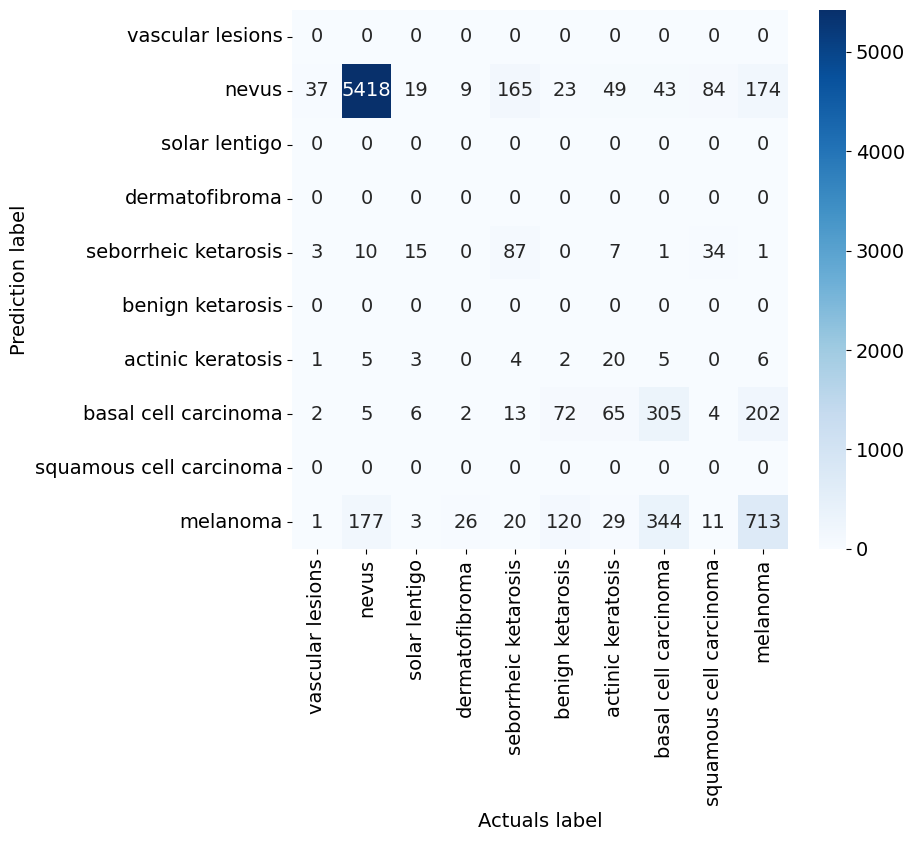

Sensitivity: 0.7841
Specificity: 0.9760
Precision: 0.7841
NPV: 0.9760
PPV: 0.7841
FNR: 0.2159
FPR: 0.0240
F1: 0.7841
Recall micro: 0.7841
Recall macro: 0.2471
Precision micro: 0.7841
Precision macro: 0.2830
F1 score micro: 0.7841
F1 score macro: 0.2511
Jaccard score micro: 0.6448
Jaccard score macro: 0.1891
Accuracy score: 0.7841
Matthews corrcoef: 0.5591
Specificity macro: 0.9618
Specificity micro: 0.9760
Specificity weighted: 0.8337
Specificity none - class vascular lesions (0): 1.0000
Specificity none - class nevus (1): 0.7791
Specificity none - class solar lentigo (2): 1.0000
Specificity none - class dermatofibroma (3): 1.0000
Specificity none - class seborrheic ketarosis (4): 0.9912
Specificity none - class benign ketarosis (5): 1.0000
Specificity none - class actinic keratosis (6): 0.9968
Specificity none - class basal cell carcinoma (7): 0.9515
Specificity none - class squamous cell carcinoma (8): 1.0000
Specificity none - class melanoma (9): 0.8992


C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [40]:
actuals = []
predictions = []

test_NN(STUD_Model_1, testloader)

torch.save(actuals, 'STUD_Model_1\\actuals.pt')
torch.save(predictions, 'STUD_Model_1\\predictions.pt')

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

torch.save(matrix, 'STUD_Model_1\\matrix.pt')

test_metric()

In [33]:
class Classification_MM(nn.Module):
    def __init__(self):
        super(Classification_MM, self).__init__()
        
        self.layer_1 = nn.Linear(3, 64)
        self.relu1 = nn.ReLU()
        self.batchnorm1 = nn.BatchNorm1d(64)
        
        self.layer_2 = nn.Linear(64, 32)
        self.relu2 = nn.ReLU()
        self.batchnorm2 = nn.BatchNorm1d(32)
        
        self.layer_out = nn.Linear(32, num_classes) 
        
        
    def forward(self, inputs):
        x = self.layer_1(inputs)
        x = self.relu1(x)
        x = self.batchnorm1(x)
        
        x = self.layer_2(x)
        x = self.relu2(x)
        x = self.batchnorm2(x)
        
        x = self.layer_out(x)
        
        return x

Classification_MM = Classification_MM()

class Net(nn.Module):

   def __init__(self):
      super(Net, self).__init__()
      self.layer1 = nn.Sequential(
         nn.Conv2d(3, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(64, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.layer2 = nn.Sequential(
         nn.Conv2d(64, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(128, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.pool1 = nn.AdaptiveAvgPool2d(output_size=(1,1))
      self.fc1 = nn.Linear(128, 32)
      self.fc2 = nn.Linear(32, num_classes)
      self.dropout_rate = 0.5
   
   def forward(self, x):
      x = self.layer1(x)
      x = self.layer2(x)
      x = self.pool1(x)
      x = x.view(x.size(0), -1)
      x = self.fc1(x)
      x = self.fc2(x)
       
      return x
       
LightNN = Net()
    
class MultimodalNN_light(nn.Module):
    def __init__(self):
        super(MultimodalNN_light, self).__init__()
        
        self.CNN = LightNN
       
        self.meta_net = Classification_MM
        
        self.out = nn.Linear(num_classes+num_classes, num_classes)
                
    def forward(self, img , tab):
        
        img = self.CNN(img) 
        img = img.reshape(img.shape[0], -1)
        
        tab = self.meta_net(tab)
        
        x = torch.cat((img, tab),1)
        x = self.out(x)
        
        return x

torch.manual_seed(42)
STUD_Model_2 = MultimodalNN_light().to(device)

model_name = 'BestModel_student2.pth'
model_weights = torch.load(model_name, device)
STUD_Model_2.load_state_dict(model_weights)
STUD_Model_2 = STUD_Model_2.to(device)

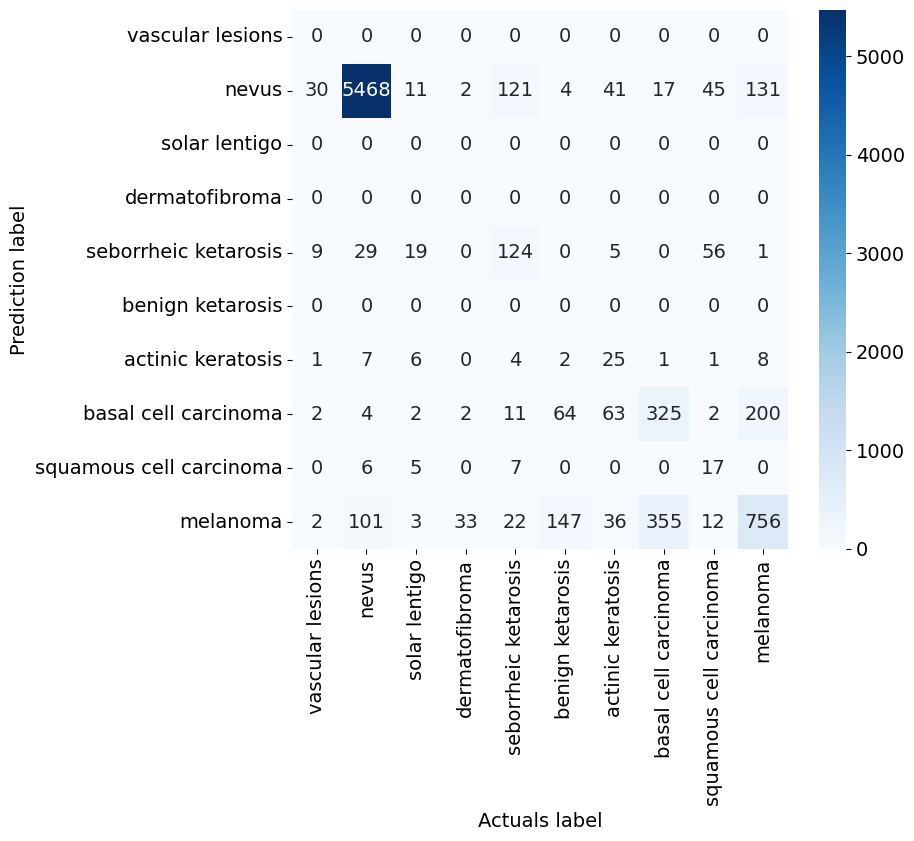

Sensitivity: 0.8047
Specificity: 0.9783
Precision: 0.8047
NPV: 0.9783
PPV: 0.8047
FNR: 0.1953
FPR: 0.0217
F1: 0.8047
Recall micro: 0.8047
Recall macro: 0.2833
Precision micro: 0.8047
Precision macro: 0.3379
F1 score micro: 0.8047
F1 score macro: 0.2906
Jaccard score micro: 0.6732
Jaccard score macro: 0.2179
Accuracy score: 0.8047
Matthews corrcoef: 0.6093
Specificity macro: 0.9688
Specificity micro: 0.9783
Specificity weighted: 0.8836
Specificity none - class vascular lesions (0): 1.0000
Specificity none - class nevus (1): 0.8527
Specificity none - class solar lentigo (2): 1.0000
Specificity none - class dermatofibroma (3): 1.0000
Specificity none - class seborrheic ketarosis (4): 0.9852
Specificity none - class benign ketarosis (5): 1.0000
Specificity none - class actinic keratosis (6): 0.9963
Specificity none - class basal cell carcinoma (7): 0.9542
Specificity none - class squamous cell carcinoma (8): 0.9978
Specificity none - class melanoma (9): 0.9019


C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [41]:
actuals = []
predictions = []

test_NN(STUD_Model_2, testloader)

torch.save(actuals, 'STUD_Model_2\\actuals.pt')
torch.save(predictions, 'STUD_Model_2\\predictions.pt')

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

torch.save(matrix, 'STUD_Model_2\\matrix.pt')

test_metric()

In [35]:
class Classification_MM(nn.Module):
    def __init__(self):
        super(Classification_MM, self).__init__()
        
        self.layer_1 = nn.Linear(3, 64)
        self.relu1 = nn.ReLU()
        self.batchnorm1 = nn.BatchNorm1d(64)
        
        self.layer_2 = nn.Linear(64, 32)
        self.relu2 = nn.ReLU()
        self.batchnorm2 = nn.BatchNorm1d(32)
        
        self.layer_out = nn.Linear(32, num_classes) 
        
        
    def forward(self, inputs):
        x = self.layer_1(inputs)
        x = self.relu1(x)
        x = self.batchnorm1(x)
        
        x = self.layer_2(x)
        x = self.relu2(x)
        x = self.batchnorm2(x)
        
        x = self.layer_out(x)
        
        return x

Classification_MM = Classification_MM()

class Net(nn.Module):

   def __init__(self):
      super(Net, self).__init__()
      self.layer1 = nn.Sequential(
         nn.Conv2d(3, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(64, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.layer2 = nn.Sequential(
         nn.Conv2d(64, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(128, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.pool1 = nn.AdaptiveAvgPool2d(output_size=(1,1))
      self.fc1 = nn.Linear(128, 32)
      self.fc2 = nn.Linear(32, num_classes)
      self.dropout_rate = 0.5
   
   def forward(self, x):
      x = self.layer1(x)
      x = self.layer2(x)
      x = self.pool1(x)
      x = x.view(x.size(0), -1)
      x = self.fc1(x)
      x = self.fc2(x)
       
      return x
       
LightNN = Net()
    
class MultimodalNN_light(nn.Module):
    def __init__(self):
        super(MultimodalNN_light, self).__init__()
        
        self.CNN = LightNN
       
        self.meta_net = Classification_MM
        
        self.out = nn.Linear(num_classes+num_classes, num_classes)
                
    def forward(self, img , tab):
        
        img = self.CNN(img) 
        img = img.reshape(img.shape[0], -1)
        
        tab = self.meta_net(tab)
        
        x = torch.cat((img, tab),1)
        x = self.out(x)
        
        return x

torch.manual_seed(42)
STUD_Model_3 = MultimodalNN_light().to(device)

model_name = 'BestModel_student3.pth'
model_weights = torch.load(model_name, device)
STUD_Model_3.load_state_dict(model_weights)
STUD_Model_3 = STUD_Model_3.to(device)

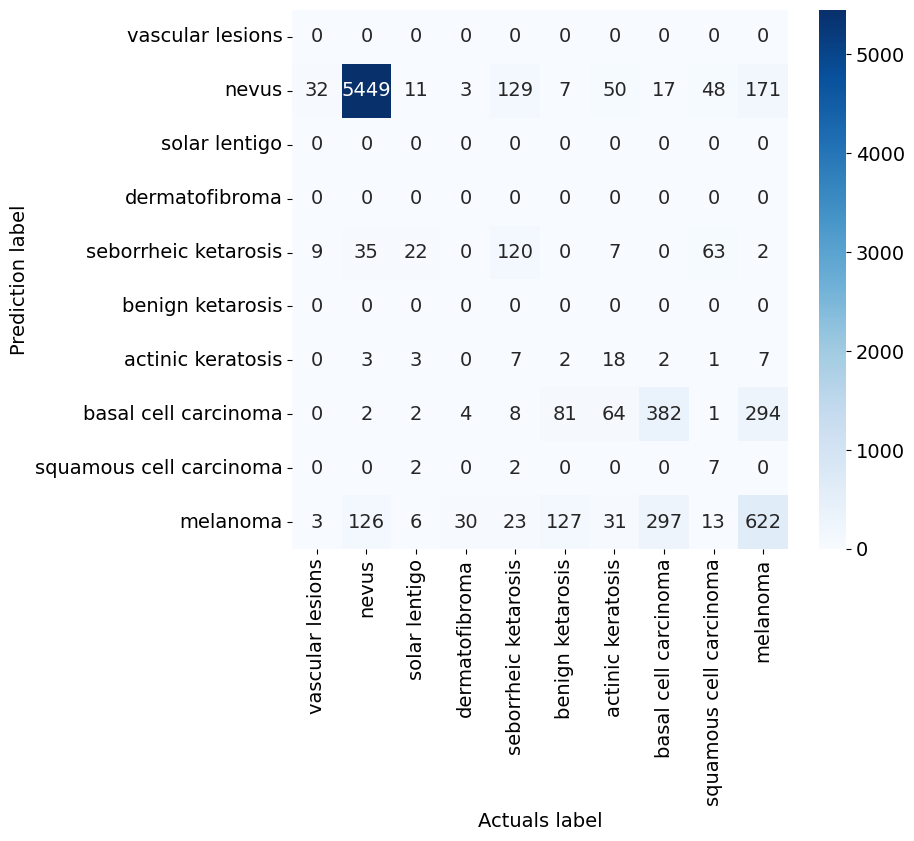

Sensitivity: 0.7907
Specificity: 0.9767
Precision: 0.7907
NPV: 0.9767
PPV: 0.7907
FNR: 0.2093
FPR: 0.0233
F1: 0.7907
Recall micro: 0.7907
Recall macro: 0.2659
Precision micro: 0.7907
Precision macro: 0.3384
F1 score micro: 0.7907
F1 score macro: 0.2671
Jaccard score micro: 0.6538
Jaccard score macro: 0.2006
Accuracy score: 0.7907
Matthews corrcoef: 0.5785
Specificity macro: 0.9658
Specificity micro: 0.9767
Specificity weighted: 0.8671
Specificity none - class vascular lesions (0): 1.0000
Specificity none - class nevus (1): 0.8286
Specificity none - class solar lentigo (2): 1.0000
Specificity none - class dermatofibroma (3): 1.0000
Specificity none - class seborrheic ketarosis (4): 0.9829
Specificity none - class benign ketarosis (5): 1.0000
Specificity none - class actinic keratosis (6): 0.9969
Specificity none - class basal cell carcinoma (7): 0.9404
Specificity none - class squamous cell carcinoma (8): 0.9995
Specificity none - class melanoma (9): 0.9095


C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [42]:
actuals = []
predictions = []

test_NN(STUD_Model_3, testloader)

torch.save(actuals, 'STUD_Model_3\\actuals.pt')
torch.save(predictions, 'STUD_Model_3\\predictions.pt')

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

torch.save(matrix, 'STUD_Model_3\\matrix.pt')

test_metric()

In [43]:
class Classification_MM(nn.Module):
    def __init__(self):
        super(Classification_MM, self).__init__()
        
        self.layer_1 = nn.Linear(3, 64)
        self.relu1 = nn.ReLU()
        self.batchnorm1 = nn.BatchNorm1d(64)
        
        self.layer_2 = nn.Linear(64, 32)
        self.relu2 = nn.ReLU()
        self.batchnorm2 = nn.BatchNorm1d(32)
        
        self.layer_out = nn.Linear(32, num_classes) 
        
        
    def forward(self, inputs):
        x = self.layer_1(inputs)
        x = self.relu1(x)
        x = self.batchnorm1(x)
        
        x = self.layer_2(x)
        x = self.relu2(x)
        x = self.batchnorm2(x)
        
        x = self.layer_out(x)
        
        return x

Classification_MM = Classification_MM()

class Net(nn.Module):

   def __init__(self):
      super(Net, self).__init__()
      self.layer1 = nn.Sequential(
         nn.Conv2d(3, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(64, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.layer2 = nn.Sequential(
         nn.Conv2d(64, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(128, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.pool1 = nn.AdaptiveAvgPool2d(output_size=(1,1))
      self.fc1 = nn.Linear(128, 32)
      self.fc2 = nn.Linear(32, num_classes)
      self.dropout_rate = 0.5
   
   def forward(self, x):
      x = self.layer1(x)
      x = self.layer2(x)
      x = self.pool1(x)
      x = x.view(x.size(0), -1)
      x = self.fc1(x)
      x = self.fc2(x)
       
      return x
       
LightNN = Net()
    
class MultimodalNN_light(nn.Module):
    def __init__(self):
        super(MultimodalNN_light, self).__init__()
        
        self.CNN = LightNN
       
        self.meta_net = Classification_MM
        
        self.out = nn.Linear(num_classes+num_classes, num_classes)
                
    def forward(self, img , tab):
        
        img = self.CNN(img) 
        img = img.reshape(img.shape[0], -1)
        
        tab = self.meta_net(tab)
        
        x = torch.cat((img, tab),1)
        x = self.out(x)
        
        return x

torch.manual_seed(42)
STUD_Model_4 = MultimodalNN_light().to(device)

model_name = 'BestModel_student4.pth'
model_weights = torch.load(model_name, device)
STUD_Model_4.load_state_dict(model_weights)
STUD_Model_4 = STUD_Model_4.to(device)

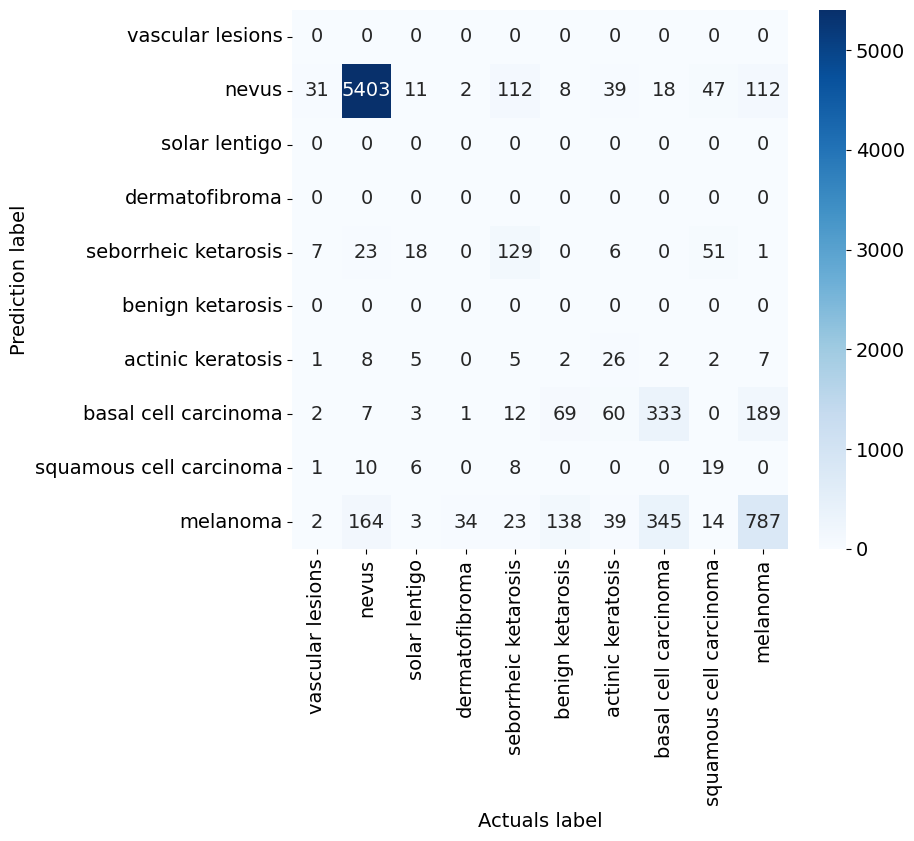

Sensitivity: 0.8025
Specificity: 0.9781
Precision: 0.8025
NPV: 0.9781
PPV: 0.8025
FNR: 0.1975
FPR: 0.0219
F1: 0.8025
Recall micro: 0.8025
Recall macro: 0.2900
Precision micro: 0.8025
Precision macro: 0.3364
F1 score micro: 0.8025
F1 score macro: 0.2963
Jaccard score micro: 0.6702
Jaccard score macro: 0.2220
Accuracy score: 0.8025
Matthews corrcoef: 0.6094
Specificity macro: 0.9691
Specificity micro: 0.9781
Specificity weighted: 0.8882
Specificity none - class vascular lesions (0): 1.0000
Specificity none - class nevus (1): 0.8608
Specificity none - class solar lentigo (2): 1.0000
Specificity none - class dermatofibroma (3): 1.0000
Specificity none - class seborrheic ketarosis (4): 0.9868
Specificity none - class benign ketarosis (5): 1.0000
Specificity none - class actinic keratosis (6): 0.9961
Specificity none - class basal cell carcinoma (7): 0.9551
Specificity none - class squamous cell carcinoma (8): 0.9970
Specificity none - class melanoma (9): 0.8949


C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [44]:
actuals = []
predictions = []

test_NN(STUD_Model_4, testloader)

torch.save(actuals, 'STUD_Model_4\\actuals.pt')
torch.save(predictions, 'STUD_Model_4\\predictions.pt')

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

torch.save(matrix, 'STUD_Model_4\\matrix.pt')

test_metric()

In [45]:
class Classification_MM(nn.Module):
    def __init__(self):
        super(Classification_MM, self).__init__()
        
        self.layer_1 = nn.Linear(3, 64)
        self.relu1 = nn.ReLU()
        self.batchnorm1 = nn.BatchNorm1d(64)
        
        self.layer_2 = nn.Linear(64, 32)
        self.relu2 = nn.ReLU()
        self.batchnorm2 = nn.BatchNorm1d(32)
        
        self.layer_out = nn.Linear(32, num_classes) 
        
        
    def forward(self, inputs):
        x = self.layer_1(inputs)
        x = self.relu1(x)
        x = self.batchnorm1(x)
        
        x = self.layer_2(x)
        x = self.relu2(x)
        x = self.batchnorm2(x)
        
        x = self.layer_out(x)
        
        return x

Classification_MM = Classification_MM()

class Net(nn.Module):

   def __init__(self):
      super(Net, self).__init__()
      self.layer1 = nn.Sequential(
         nn.Conv2d(3, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(64, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.layer2 = nn.Sequential(
         nn.Conv2d(64, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(128, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.pool1 = nn.AdaptiveAvgPool2d(output_size=(1,1))
      self.fc1 = nn.Linear(128, 32)
      self.fc2 = nn.Linear(32, num_classes)
      self.dropout_rate = 0.5
   
   def forward(self, x):
      x = self.layer1(x)
      x = self.layer2(x)
      x = self.pool1(x)
      x = x.view(x.size(0), -1)
      x = self.fc1(x)
      x = self.fc2(x)
       
      return x
       
LightNN = Net()
    
class MultimodalNN_light(nn.Module):
    def __init__(self):
        super(MultimodalNN_light, self).__init__()
        
        self.CNN = LightNN
       
        self.meta_net = Classification_MM
        
        self.out = nn.Linear(num_classes+num_classes, num_classes)
                
    def forward(self, img , tab):
        
        img = self.CNN(img) 
        img = img.reshape(img.shape[0], -1)
        
        tab = self.meta_net(tab)
        
        x = torch.cat((img, tab),1)
        x = self.out(x)
        
        return x

torch.manual_seed(42)
STUD_Model_5 = MultimodalNN_light().to(device)

model_name = 'BestModel_student5.pth'
model_weights = torch.load(model_name, device)
STUD_Model_5.load_state_dict(model_weights)
STUD_Model_5 = STUD_Model_5.to(device)

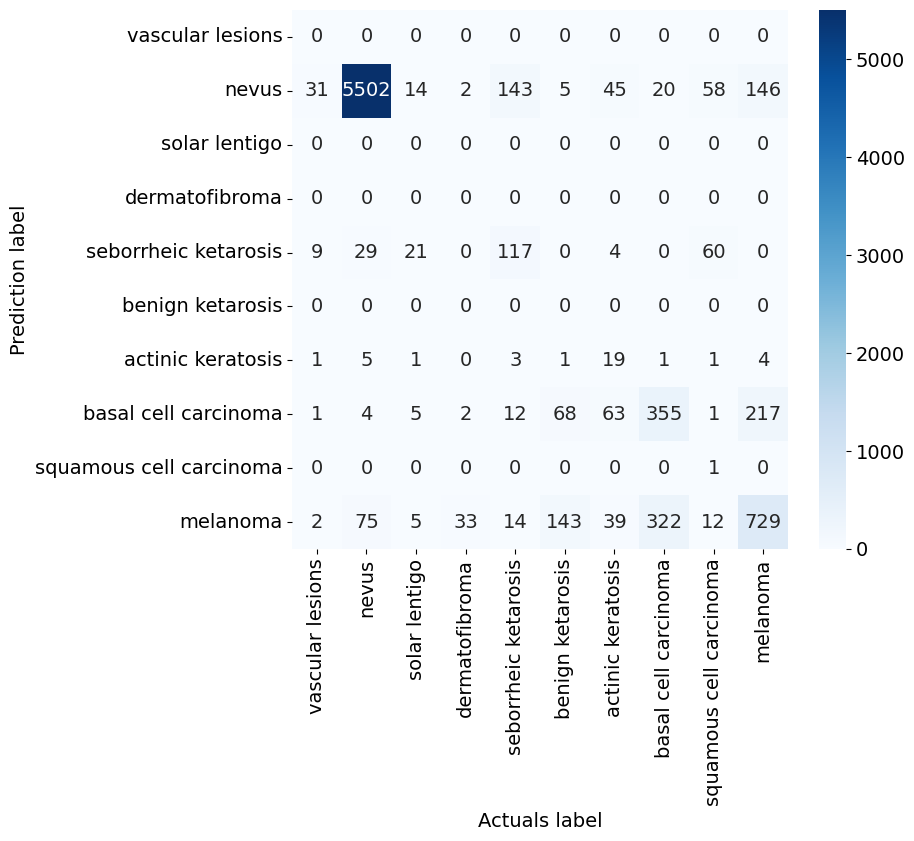

Sensitivity: 0.8056
Specificity: 0.9784
Precision: 0.8056
NPV: 0.9784
PPV: 0.8056
FNR: 0.1944
FPR: 0.0216
F1: 0.8056
Recall micro: 0.8056
Recall macro: 0.2678
Precision micro: 0.8056
Precision macro: 0.3956
F1 score micro: 0.8056
F1 score macro: 0.2680
Jaccard score micro: 0.6745
Jaccard score macro: 0.2048
Accuracy score: 0.8056
Matthews corrcoef: 0.6065
Specificity macro: 0.9675
Specificity micro: 0.9784
Specificity weighted: 0.8693
Specificity none - class vascular lesions (0): 1.0000
Specificity none - class nevus (1): 0.8300
Specificity none - class solar lentigo (2): 1.0000
Specificity none - class dermatofibroma (3): 1.0000
Specificity none - class seborrheic ketarosis (4): 0.9847
Specificity none - class benign ketarosis (5): 1.0000
Specificity none - class actinic keratosis (6): 0.9979
Specificity none - class basal cell carcinoma (7): 0.9512
Specificity none - class squamous cell carcinoma (8): 1.0000
Specificity none - class melanoma (9): 0.9110


C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [46]:
actuals = []
predictions = []

test_NN(STUD_Model_5, testloader)

torch.save(actuals, 'STUD_Model_5\\actuals.pt')
torch.save(predictions, 'STUD_Model_5\\predictions.pt')

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

torch.save(matrix, 'STUD_Model_5\\matrix.pt')

test_metric()

In [45]:
def test(model, test_loader, device):

    start_time_glob = time.time()
    model.to(device)
    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():
        for i, data in enumerate(test_loader):
            inputs, feats, labels, name = data
            inputs, feats, labels = inputs.to(device), feats.to(device), labels.to(device)

            outputs = model(inputs, feats)
            
            _, predicted = torch.max(outputs.data, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total
    
    time_glob = time.time()-start_time_glob
    print('_' * 60)
    print ('Время тестирования: {}'.format(time.strftime("%H:%M:%S", time.gmtime(time_glob))))
    print ('Время тестирования в секундах: {:.6f}\n'.format(time_glob))
    return accuracy

test_1 = test(NET_deep, testloader, device)
print(f"Точность модели-учителя: {test_1:.2f}%")

test_2 = test(NET_light, testloader, device)
print(f"Точность модели-ученика без учителя: {test_2:.2f}%")

test_3 = test(STUD_Model_1, testloader, device)
print(f"Точность модели-ученика со значениями Т=1, alpha=0.5: {test_3:.2f}%")

test_4 = test(STUD_Model_2, testloader, device)
print(f"Точность модели-ученика со значениями Т=2, alpha=0.5: {test_4:.2f}%")

test_5 = test(STUD_Model_3, testloader, device)
print(f"Точность модели-ученика со значениями Т=5, alpha=0.5: {test_5:.2f}%")

test_6 = test(STUD_Model_4, testloader, device)
print(f"Точность модели-ученика со значениями Т=2, alpha=0.25: {test_6:.2f}%")

test_7 = test(STUD_Model_5, testloader, device)
print(f"Точность модели-ученика со значениями Т=2, alpha=0.75: {test_7:.2f}%")

____________________________________________________________
Время тестирования: 00:00:11
Время тестирования в секундах: 11.499197

Точность модели-учителя: 82.28%
____________________________________________________________
Время тестирования: 00:00:09
Время тестирования в секундах: 9.485668

Точность модели-ученика без учителя: 76.45%
____________________________________________________________
Время тестирования: 00:00:09
Время тестирования в секундах: 9.554679

Точность модели-ученика со значениями Т=1, alpha=0.5: 77.54%
____________________________________________________________
Время тестирования: 00:00:09
Время тестирования в секундах: 9.537312

Точность модели-ученика со значениями Т=2, alpha=0.5: 79.94%
____________________________________________________________
Время тестирования: 00:00:09
Время тестирования в секундах: 9.540491

Точность модели-ученика со значениями Т=5, alpha=0.5: 79.15%
____________________________________________________________
Время тестирования: 00:0